# Task 1 — Employee Attrition Data Audit & Exploration

**Objective:** identify and treat justified data-quality issues, document missingness/outliers/class imbalance/leakage, and save a plain-language audit report.

**Flow:** load → profile → investigate duplicates → validate target → review leakage → investigate and treat missingness → compare IQR/z-score outliers → document decisions → save reports.

## 1. Import Libraries

Import pandas, NumPy, plotting, and path utilities

In [106]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
from pathlib import Path

pd.set_option("display.max_columns", 100)

## 2. Load Dataset

Load the workbook from `data/raw`. Keep the original dataset unchanged.

In [ ]:
from pathlib import Path
import pandas as pd


PROJECT_ROOT = Path.cwd().parent

file_path = PROJECT_ROOT / "data" / "raw" / "02_CortexHR_AI_ML_Dataset.xlsx"

print("Project root:", PROJECT_ROOT)
print("File path:", file_path)
print("File exists:", file_path.exists())

if not file_path.exists():
    raise FileNotFoundError(
        f"Excel file not found at: {file_path}\n"
        "Check the filename and location inside data/raw."
    )

df_raw = pd.read_excel(
    file_path,
    sheet_name="attrition_dataset"
)

df = df_raw.copy()

print("\nDataset loaded successfully!")
print("Shape:", df.shape)
display(df.head())

Project root: d:\employee-attrition-ml
File path: d:\employee-attrition-ml\data\raw\02_CortexHR_AI_ML_Dataset.xlsx
File exists: True

Dataset loaded successfully!
Shape: (2389, 42)


,row_id,employee_id,observation_date,department_id,role_id,job_level,work_location,work_mode,employment_type,highest_education,tenure_months,total_experience_years,previous_employers_count,commute_distance_km,annual_fixed_pay,comp_ratio,raises_received,last_raise_pct,months_since_last_raise,promotions_received,months_since_last_promotion,internal_transfers,last_performance_rating,last_engagement_score,manager_changes_12m,training_hours_12m,attendance_rate_3m,late_arrivals_3m,avg_overtime_hours_per_month_3m,avg_hours_worked_3m,wfh_share_3m,unpaid_leave_days_6m,paid_leave_days_6m,dept_attrition_rate_prior_12m,left_within_12m,voluntary_left_within_12m,source,exit_date,resignation_date,exit_reason,exit_interview_done,fnf_settlement_amount
0,1,EMP-0002,2025-09-30,D08,R047,4,Pune,Remote,Permanent,B.E. Computer Science,164,30.8,1,12.2,1733520,0.989,6,6.3,5,0,NaN,1,3.0,2.5,0,34.0,0.9219,3,0.00,8.01,0.891,2.0,5,0.2353,0,0,master_employee_snapshot,NaT,NaT,NaN,NaN,NaN
1,2,EMP-0004,2025-09-30,D03,R017,3,Erode,Hybrid,Permanent,MCA,162,17.5,1,NaN,1247256,0.854,6,9.6,5,0,NaN,0,4.0,2.4,0,48.1,0.9688,1,0.00,8.35,0.469,1.0,4,0.0556,0,0,master_employee_snapshot,NaT,NaT,NaN,NaN,NaN
2,3,EMP-0011,2025-09-30,D07,R039,1,Kochi,Hybrid,Permanent,M.A. Social Work,154,12.8,0,44.5,288492,0.872,7,9.5,5,0,NaN,0,4.0,2.7,0,57.7,0.9453,0,4.33,8.23,0.297,1.0,7,0.0000,0,0,master_employee_snapshot,NaT,NaT,NaN,NaN,NaN
3,4,EMP-0012,2025-09-30,D01,R004,2,Chennai,Onsite,Permanent,B.Tech Information Technology,152,17.2,2,27.3,646980,0.886,6,3.1,5,0,NaN,0,2.0,3.6,0,10.9,0.9375,4,0.00,8.34,0.016,0.0,8,0.1448,1,1,master_employee_snapshot,2026-04-23,2026-03-24,Work-Life Balance,Y,117098.85
4,5,EMP-0013,2025-09-30,D04,R023,2,Chennai,Onsite,Permanent,B.E. Mechanical,152,17.4,1,25.0,582168,0.797,6,11.2,5,0,NaN,0,4.0,2.5,0,16.0,0.8906,10,0.00,7.81,0.000,0.0,7,0.2051,0,0,master_employee_snapshot,NaT,NaT,NaN,NaN,NaN


## 3. Basic Dataset Profile

Review row/column counts, data types, unique values, and missingness.

In [108]:
print("Rows:", df.shape[0])
print("Columns:", df.shape[1])

df.info()

display(
    pd.DataFrame({
        "dtype": df.dtypes,
        "non_missing": df.notna().sum(),
        "missing": df.isna().sum(),
        "unique": df.nunique()
    })
)

print("Exact duplicate rows:", df.duplicated().sum())

Rows: 2389
Columns: 42
<class 'pandas.core.frame.DataFrame'>
RangeIndex: 2389 entries, 0 to 2388
Data columns (total 42 columns):
 #   Column                           Non-Null Count  Dtype         
---  ------                           --------------  -----         
 0   row_id                           2389 non-null   int64         
 1   employee_id                      2389 non-null   object        
 2   observation_date                 2389 non-null   datetime64[ns]
 3   department_id                    2389 non-null   object        
 4   role_id                          2389 non-null   object        
 5   job_level                        2389 non-null   int64         
 6   work_location                    2389 non-null   object        
 7   work_mode                        2389 non-null   object        
 8   employment_type                  2389 non-null   object        
 9   highest_education                2374 non-null   object        
 10  tenure_months                    2389

,dtype,non_missing,missing,unique
row_id,int64,2389,0,2389
employee_id,object,2389,0,2383
observation_date,datetime64[ns],2389,0,1135
department_id,object,2389,0,10
role_id,object,2389,0,48
job_level,int64,2389,0,6
work_location,object,2389,0,16
work_mode,object,2389,0,3
employment_type,object,2389,0,2
highest_education,object,2374,15,27


Exact duplicate rows: 0


In [169]:
duplicate_ids = df[
    df.duplicated(subset=["employee_id"], keep=False)
].sort_values("employee_id")

print("Rows with repeated employee IDs:", len(duplicate_ids))
print("Repeated unique employees:", duplicate_ids["employee_id"].nunique())

display(duplicate_ids)

Rows with repeated employee IDs: 0
Repeated unique employees: 0


,row_id,employee_id,observation_date,department_id,role_id,job_level,work_location,work_mode,employment_type,highest_education,tenure_months,total_experience_years,previous_employers_count,commute_distance_km,annual_fixed_pay,comp_ratio,raises_received,last_raise_pct,months_since_last_raise,promotions_received,months_since_last_promotion,internal_transfers,last_performance_rating,last_engagement_score,manager_changes_12m,training_hours_12m,attendance_rate_3m,late_arrivals_3m,avg_overtime_hours_per_month_3m,avg_hours_worked_3m,wfh_share_3m,unpaid_leave_days_6m,paid_leave_days_6m,dept_attrition_rate_prior_12m,left_within_12m,voluntary_left_within_12m,source,exit_date,resignation_date,exit_reason,exit_interview_done,fnf_settlement_amount,never_promoted


## 4. Missing-Value Profile

Measure missing values in every column. These are the baseline figures before treatment.

In [109]:
missing_summary = pd.DataFrame({
    "missing_count": df.isna().sum(),
    "missing_percent": (df.isna().mean() * 100).round(2),
    "dtype": df.dtypes.astype(str),
    "unique_non_null": df.nunique(dropna=True)
}).sort_values("missing_count", ascending=False)
display(missing_summary[missing_summary["missing_count"] > 0])

,missing_count,missing_percent,dtype,unique_non_null
resignation_date,2068,86.56,datetime64[ns],296
exit_reason,2040,85.39,object,11
exit_date,2040,85.39,datetime64[ns],307
exit_interview_done,2040,85.39,object,2
fnf_settlement_amount,2040,85.39,float64,349
months_since_last_promotion,1459,61.07,float64,94
last_engagement_score,528,22.10,float64,38
last_raise_pct,202,8.46,float64,184
last_performance_rating,182,7.62,float64,5
commute_distance_km,55,2.30,float64,372


## 5. Check Exact Duplicate Rows


In [110]:
exact_duplicate_count = int(df.duplicated().sum())
print("Exact duplicate rows beyond first occurrence:", exact_duplicate_count)
duplicate_mask = df.duplicated(keep=False)
print("Rows involved in exact duplicates:", int(duplicate_mask.sum()))
if duplicate_mask.any():
    display(df.loc[duplicate_mask])

Exact duplicate rows beyond first occurrence: 0
Rows involved in exact duplicates: 0


## 6. Investigate Repeated Employees

Compare records after excluding `row_id`, a technical identifier. Repeated IDs are not automatically duplicates.

In [111]:
comparison_columns = [c for c in df.columns if c != "row_id"]
employee_counts = df["employee_id"].value_counts()
repeated_ids = employee_counts[employee_counts > 1].index
repeated_records = df[df["employee_id"].isin(repeated_ids)].sort_values(["employee_id", "row_id"])
comparison_summary = repeated_records.groupby("employee_id")[comparison_columns].nunique(dropna=False)
identical_groups = comparison_summary.le(1).all(axis=1)

print("Unique employee IDs:", df["employee_id"].nunique())
print("Repeated employee groups:", len(repeated_ids))
print("Groups identical apart from row_id:", int(identical_groups.sum()))
print("Groups with feature differences:", int((~identical_groups).sum()))
display(repeated_records)
display(comparison_summary.loc[~identical_groups])

Unique employee IDs: 2383
Repeated employee groups: 6
Groups identical apart from row_id: 6
Groups with feature differences: 0


,row_id,employee_id,observation_date,department_id,role_id,job_level,work_location,work_mode,employment_type,highest_education,tenure_months,total_experience_years,previous_employers_count,commute_distance_km,annual_fixed_pay,comp_ratio,raises_received,last_raise_pct,months_since_last_raise,promotions_received,months_since_last_promotion,internal_transfers,last_performance_rating,last_engagement_score,manager_changes_12m,training_hours_12m,attendance_rate_3m,late_arrivals_3m,avg_overtime_hours_per_month_3m,avg_hours_worked_3m,wfh_share_3m,unpaid_leave_days_6m,paid_leave_days_6m,dept_attrition_rate_prior_12m,left_within_12m,voluntary_left_within_12m,source,exit_date,resignation_date,exit_reason,exit_interview_done,fnf_settlement_amount
26,27,EMP-0060,2025-09-30,D01,R006,3,Bengaluru,Hybrid,Permanent,MCA,111,17.6,2,8.8,1464708,1.003,6,8.1,5,0,NaN,0,3.0,3.1,0,16.2,1.0000,3,0.00,8.65,0.438,0.0,1,0.1448,0,0,master_employee_snapshot,NaT,NaT,NaN,NaN,NaN
2386,2387,EMP-0060,2025-09-30,D01,R006,3,Bengaluru,Hybrid,Permanent,MCA,111,17.6,2,8.8,1464708,1.003,6,8.1,5,0,NaN,0,3.0,3.1,0,16.2,1.0000,3,0.00,8.65,0.438,0.0,1,0.1448,0,0,master_employee_snapshot,NaT,NaT,NaN,NaN,NaN
100,101,EMP-0237,2025-09-30,D07,R040,2,Chennai,Remote,Permanent,B.Sc,51,9.4,1,7.5,486732,1.000,4,2.0,5,0,NaN,1,2.0,3.5,0,38.5,0.9844,1,11.67,9.07,0.922,0.0,9,0.0000,0,0,master_employee_snapshot,NaT,NaT,NaN,NaN,NaN
2387,2388,EMP-0237,2025-09-30,D07,R040,2,Chennai,Remote,Permanent,B.Sc,51,9.4,1,7.5,486732,1.000,4,2.0,5,0,NaN,1,2.0,3.5,0,38.5,0.9844,1,11.67,9.07,0.922,0.0,9,0.0000,0,0,master_employee_snapshot,NaT,NaT,NaN,NaN,NaN
101,102,EMP-0238,2025-09-30,D01,R004,2,Chennai,Remote,Permanent,M.Tech,51,5.3,2,12.5,795984,1.090,5,11.4,5,0,NaN,0,4.0,1.9,0,8.2,0.9688,3,0.00,8.62,0.922,2.0,18,0.1448,0,0,master_employee_snapshot,NaT,NaT,NaN,NaN,NaN
2384,2385,EMP-0238,2025-09-30,D01,R004,2,Chennai,Remote,Permanent,M.Tech,51,5.3,2,12.5,795984,1.090,5,11.4,5,0,NaN,0,4.0,1.9,0,8.2,0.9688,3,0.00,8.62,0.922,2.0,18,0.1448,0,0,master_employee_snapshot,NaT,NaT,NaN,NaN,NaN
150,151,EMP-0325,2025-09-30,D03,R019,4,Chennai,Hybrid,Permanent,MCA,38,19.1,0,14.6,3157536,1.247,3,11.1,5,0,NaN,0,4.0,3.3,0,25.2,0.9688,7,0.00,8.43,0.422,3.5,1,0.0556,0,0,master_employee_snapshot,NaT,NaT,NaN,NaN,NaN
2383,2384,EMP-0325,2025-09-30,D03,R019,4,Chennai,Hybrid,Permanent,MCA,38,19.1,0,14.6,3157536,1.247,3,11.1,5,0,NaN,0,4.0,3.3,0,25.2,0.9688,7,0.00,8.43,0.422,3.5,1,0.0556,0,0,master_employee_snapshot,NaT,NaT,NaN,NaN,NaN
250,251,EMP-0483,2025-09-30,D09,R053,4,Bengaluru,Onsite,Permanent,MBA,21,12.6,1,10.2,1598520,0.966,1,9.5,5,0,NaN,0,4.0,2.5,0,46.6,0.9844,2,0.00,8.70,0.031,0.0,1,0.2069,0,0,master_employee_snapshot,NaT,NaT,NaN,NaN,NaN
2385,2386,EMP-0483,2025-09-30,D09,R053,4,Bengaluru,Onsite,Permanent,MBA,21,12.6,1,10.2,1598520,0.966,1,9.5,5,0,NaN,0,4.0,2.5,0,46.6,0.9844,2,0.00,8.70,0.031,0.0,1,0.2069,0,0,master_employee_snapshot,NaT,NaT,NaN,NaN,NaN


,employee_id,observation_date,department_id,role_id,job_level,work_location,work_mode,employment_type,highest_education,tenure_months,total_experience_years,previous_employers_count,commute_distance_km,annual_fixed_pay,comp_ratio,raises_received,last_raise_pct,months_since_last_raise,promotions_received,months_since_last_promotion,internal_transfers,last_performance_rating,last_engagement_score,manager_changes_12m,training_hours_12m,attendance_rate_3m,late_arrivals_3m,avg_overtime_hours_per_month_3m,avg_hours_worked_3m,wfh_share_3m,unpaid_leave_days_6m,paid_leave_days_6m,dept_attrition_rate_prior_12m,left_within_12m,voluntary_left_within_12m,source,exit_date,resignation_date,exit_reason,exit_interview_done,fnf_settlement_amount
employee_id,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,


## 7. Validate the Target and Check Class Imbalance

Do not impute target labels. Report the distribution and retain the imbalance for honest evaluation.

Missing target labels: 0
Unexpected target values: 0


,employee_count,percentage
left_within_12m,,
0,2040,85.39
1,349,14.61


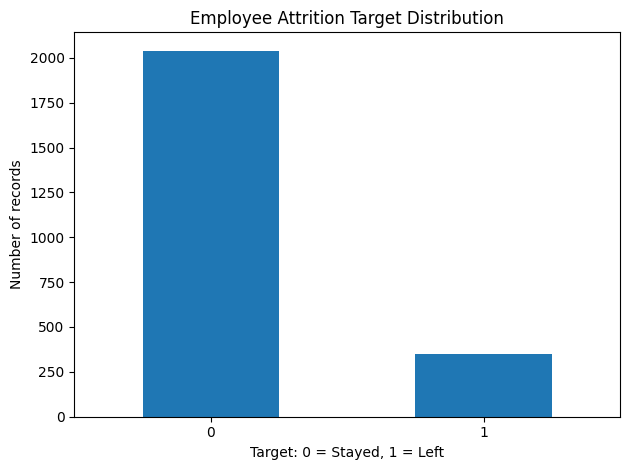

In [112]:
target = "left_within_12m"
print("Missing target labels:", int(df[target].isna().sum()))
invalid_target_mask = df[target].notna() & ~df[target].isin([0, 1])
print("Unexpected target values:", int(invalid_target_mask.sum()))

target_counts = df[target].value_counts(dropna=False).sort_index()
target_summary = pd.DataFrame({
    "employee_count": target_counts,
    "percentage": (df[target].value_counts(normalize=True, dropna=False) * 100).round(2)
})
display(target_summary)

target_counts.drop(index=[v for v in target_counts.index if pd.isna(v)], errors="ignore").plot(
    kind="bar", rot=0, title="Employee Attrition Target Distribution"
)
plt.xlabel("Target: 0 = Stayed, 1 = Left")
plt.ylabel("Number of records")
plt.tight_layout()
plt.show()

### Decision — Class imbalance

The current output shows 2,040 stayed (85.39%) and 349 left (14.61%). Do not delete majority-class rows during the audit. In Task 3, report recall, precision, F1, ROC-AUC and PR-AUC; compare class weights using training data only.

## 8. Review Leakage and Identifier Columns

Keep these fields for auditing, but exclude identifiers and outcome/post-outcome fields from early-warning predictors. Verify prediction-time availability for historical aggregates.

In [113]:
leakage_review = pd.DataFrame([
    ("row_id", "Technical identifier", "Exclude from predictors"),
    ("employee_id", "Employee identifier; potential memorization", "Exclude from predictors; use for grouping only"),
    ("observation_date", "Reference/prediction date", "Retain for time-aware validation; exclude as predictor initially"),
    ("resignation_date", "May reveal departure", "Exclude from early-warning predictors"),
    ("exit_date", "Post-outcome date", "Exclude from predictors"),
    ("exit_reason", "Recorded during/after departure", "Exclude from predictors"),
    ("exit_interview_done", "Potentially recorded after departure starts", "Exclude unless prediction-time availability is proven"),
    ("fnf_settlement_amount", "Post-exit settlement", "Exclude from predictors"),
    ("voluntary_left_within_12m", "May overlap with target definition", "Exclude until definition is verified"),
    ("dept_attrition_rate_prior_12m", "Potentially valid only if strictly historical", "Exclude until temporal construction is verified"),
], columns=["column", "risk", "decision"])
display(leakage_review)

,column,risk,decision
0,row_id,Technical identifier,Exclude from predictors
1,employee_id,Employee identifier; potential memorization,Exclude from predictors; use for grouping only
2,observation_date,Reference/prediction date,Retain for time-aware validation; exclude as p...
3,resignation_date,May reveal departure,Exclude from early-warning predictors
4,exit_date,Post-outcome date,Exclude from predictors
5,exit_reason,Recorded during/after departure,Exclude from predictors
6,exit_interview_done,Potentially recorded after departure starts,Exclude unless prediction-time availability is...
7,fnf_settlement_amount,Post-exit settlement,Exclude from predictors
8,voluntary_left_within_12m,May overlap with target definition,Exclude until definition is verified
9,dept_attrition_rate_prior_12m,Potentially valid only if strictly historical,Exclude until temporal construction is verified


## 9. Investigate Promotion-Recency Missingness

Check whether missing `months_since_last_promotion` occurs only when the employee has never been promoted.

In [114]:
promotion_check = (
    df.groupby("promotions_received", dropna=False)
      .agg(
          employee_count=("months_since_last_promotion", "size"),
          missing_recency=("months_since_last_promotion", lambda s: s.isna().sum())
      )
)
promotion_check["missing_percent"] = (
    promotion_check["missing_recency"] / promotion_check["employee_count"] * 100
).round(2)
display(promotion_check)

missing_promo = df["months_since_last_promotion"].isna()
print("Missing recency with zero promotions:",
      int((missing_promo & df["promotions_received"].eq(0)).sum()))
print("Missing recency with one or more promotions:",
      int((missing_promo & df["promotions_received"].gt(0)).sum()))

,employee_count,missing_recency,missing_percent
promotions_received,,,
0,1459,1459,100.0
1,563,0,0.0
2,229,0,0.0
3,88,0,0.0
4,38,0,0.0
5,6,0,0.0
6,5,0,0.0
7,1,0,0.0


Missing recency with zero promotions: 1459
Missing recency with one or more promotions: 0


### Decision — Promotion recency

The audit shows 1,459 missing recency values among employees with zero promotions and none among employees with promotions. Preserve these NaNs in the audit copy and create `never_promoted`; do not treat them as zero months. Confirm this business meaning with the data owner.

## 10. Create the Audit-Cleaned Copy and Apply Justified Treatments

Keep `df` unchanged. Apply documented changes to `df_clean`; do not globally impute numeric predictors using full-dataset statistics.

In [115]:
df_clean = df.copy()
cleaning_log = []

# Meaningful missingness indicator
df_clean["never_promoted"] = df_clean["promotions_received"].eq(0).astype("int8")
cleaning_log.append({
    "feature": "months_since_last_promotion",
    "issue": "Missing when promotions_received == 0",
    "action": "Preserved NaN in audit copy; created never_promoted indicator",
    "affected_rows": int(df_clean["months_since_last_promotion"].isna().sum())
})

# Education: use Unknown if accepted by the dataset's business definition
education_missing = int(df_clean["highest_education"].isna().sum())
df_clean["highest_education"] = df_clean["highest_education"].fillna("Unknown")
if education_missing:
    cleaning_log.append({
        "feature": "highest_education",
        "issue": "Education not recorded",
        "action": "Filled with Unknown",
        "affected_rows": education_missing
    })

# Negative tenure is invalid if tenure is elapsed employment months
negative_tenure = df_clean["tenure_months"] < 0
negative_tenure_count = int(negative_tenure.sum())
print("Negative tenure values:", negative_tenure_count)
if negative_tenure_count:
    df_clean.loc[negative_tenure, "tenure_months"] = np.nan
    cleaning_log.append({
        "feature": "tenure_months",
        "issue": "Negative tenure is invalid under feature definition",
        "action": "Set to NaN pending source correction; no global imputation",
        "affected_rows": negative_tenure_count
    })

print("Audit-cleaned shape before duplicate-copy treatment:", df_clean.shape)

Negative tenure values: 4
Audit-cleaned shape before duplicate-copy treatment: (2389, 43)


## 11. Treat Confirmed Duplicate Copies

The comparison indicates repeated groups are identical apart from `row_id`. This supports removing duplicate copies from the audit-cleaned copy if the export is intended to contain one row per employee-observation. The source `df` remains unchanged.

In [116]:
business_columns = [c for c in df_clean.columns if c != "row_id"]
duplicate_copy_mask = df_clean.duplicated(subset=business_columns, keep="first")
duplicate_copies_removed = int(duplicate_copy_mask.sum())

print("Duplicate copies identified:", duplicate_copies_removed)
if duplicate_copies_removed:
    df_clean = df_clean.loc[~duplicate_copy_mask].copy()
    cleaning_log.append({
        "feature": "employee-observation record",
        "issue": "Repeated records identical apart from row_id",
        "action": "Kept first copy in df_clean; preserved original df",
        "affected_rows": duplicate_copies_removed
    })

print("Rows in original data:", len(df))
print("Rows in audit-cleaned copy:", len(df_clean))
print("Repeated employee IDs remaining:", int(df_clean["employee_id"].duplicated().sum()))

Duplicate copies identified: 6
Rows in original data: 2389
Rows in audit-cleaned copy: 2383
Repeated employee IDs remaining: 0


## 12. Detect Outliers Using IQR and Z-Score

Compare two methods for salary, average hours, and tenure. Outlier flags indicate unusual values, not necessarily bad data.

In [117]:
from scipy.stats import zscore

outlier_columns = [c for c in [
    "annual_fixed_pay", "avg_hours_worked_3m", "tenure_months"
] if c in df_clean.columns]

outlier_rows = []
for col in outlier_columns:
    values = df_clean[col]
    valid = values.dropna()

    q1, q3 = valid.quantile([0.25, 0.75])
    iqr = q3 - q1
    lower, upper = q1 - 1.5 * iqr, q3 + 1.5 * iqr
    iqr_mask = ((values < lower) | (values > upper)).fillna(False)

    z_mask = pd.Series(False, index=values.index)
    if valid.nunique() > 1:
        z_vals = pd.Series(zscore(valid), index=valid.index)
        z_mask.loc[z_vals.index] = z_vals.abs() > 3

    outlier_rows.append({
        "feature": col,
        "iqr_lower": lower,
        "iqr_upper": upper,
        "iqr_count": int(iqr_mask.sum()),
        "iqr_percent": round(iqr_mask.mean() * 100, 2),
        "zscore_abs_gt_3_count": int(z_mask.sum()),
        "zscore_abs_gt_3_percent": round(z_mask.mean() * 100, 2),
        "flagged_by_both": int((iqr_mask & z_mask).sum())
    })

outlier_comparison = pd.DataFrame(outlier_rows)
display(outlier_comparison)

,feature,iqr_lower,iqr_upper,iqr_count,iqr_percent,zscore_abs_gt_3_count,zscore_abs_gt_3_percent,flagged_by_both
0,annual_fixed_pay,-990153.000,2838351.000,93,3.90,26,1.09,26
1,avg_hours_worked_3m,7.925,9.405,48,2.01,15,0.63,15
2,tenure_months,-31.500,100.500,73,3.06,45,1.89,45


## 13. Make Outlier Treatment Decisions

Retain plausible values. Investigate source units and business constraints before changing salary, working hours, or high tenure. Negative tenure has already been handled as invalid.

In [118]:
outlier_decisions = pd.DataFrame([
    ("annual_fixed_pay", "Retain IQR/z-score flags unless source validation proves an error; inspect salary units and distribution."),
    ("avg_hours_worked_3m", "Validate units and allowed range; correct only confirmed data errors."),
    ("tenure_months", "Negative values set to missing; retain plausible high tenure values."),
], columns=["feature", "treatment_decision"])
display(outlier_decisions)

,feature,treatment_decision
0,annual_fixed_pay,Retain IQR/z-score flags unless source validat...
1,avg_hours_worked_3m,Validate units and allowed range; correct only...
2,tenure_months,Negative values set to missing; retain plausib...


## 14. Recheck Remaining Missing Values

Some missingness should remain in the audit copy. Ordinary numeric predictor gaps are intentionally left for the training-only pipeline.

In [119]:
missing_after = pd.DataFrame({
    "missing_count": df_clean.isna().sum(),
    "missing_percent": (df_clean.isna().mean() * 100).round(2)
})
missing_after = missing_after[missing_after["missing_count"] > 0].sort_values("missing_count", ascending=False)
display(missing_after)

,missing_count,missing_percent
resignation_date,2062,86.53
exit_date,2034,85.35
exit_reason,2034,85.35
fnf_settlement_amount,2034,85.35
exit_interview_done,2034,85.35
months_since_last_promotion,1453,60.97
last_engagement_score,528,22.16
last_raise_pct,201,8.43
last_performance_rating,181,7.60
commute_distance_km,55,2.31


## 15. Create Cleaning Log and Data Dictionary

Record each treatment. The data dictionary below includes data type, role, and a plain-language definition placeholder that should be confirmed against the source handoff.

In [120]:
cleaning_log_df = pd.DataFrame(
    cleaning_log,
    columns=["feature", "issue", "action", "affected_rows"]
)
display(cleaning_log_df)

data_dictionary = pd.DataFrame({
    "column_name": df.columns,
    "data_type": [str(df[c].dtype) for c in df.columns],
    "non_missing_values": [int(df[c].notna().sum()) for c in df.columns],
    "unique_non_missing_values": [int(df[c].nunique(dropna=True)) for c in df.columns],
    "role": [
        "Target" if c == target else
        "Identifier" if c in ["row_id", "employee_id"] else
        "Date/reference" if c == "observation_date" else
        "Potential leakage / audit-only" if c in [
            "resignation_date", "exit_date", "exit_reason",
            "exit_interview_done", "fnf_settlement_amount",
            "voluntary_left_within_12m"
        ] else
        "Candidate predictor; verify prediction-time availability"
        for c in df.columns
    ],
    "plain_language_definition": [
        "Confirm definition against source data dictionary" for c in df.columns
    ]
})
display(data_dictionary)

,feature,issue,action,affected_rows
0,months_since_last_promotion,Missing when promotions_received == 0,Preserved NaN in audit copy; created never_pro...,1459
1,highest_education,Education not recorded,Filled with Unknown,15
2,tenure_months,Negative tenure is invalid under feature defin...,Set to NaN pending source correction; no globa...,4
3,employee-observation record,Repeated records identical apart from row_id,Kept first copy in df_clean; preserved origina...,6


,column_name,data_type,non_missing_values,unique_non_missing_values,role,plain_language_definition
0,row_id,int64,2389,2389,Identifier,Confirm definition against source data dictionary
1,employee_id,object,2389,2383,Identifier,Confirm definition against source data dictionary
2,observation_date,datetime64[ns],2389,1135,Date/reference,Confirm definition against source data dictionary
3,department_id,object,2389,10,Candidate predictor; verify prediction-time av...,Confirm definition against source data dictionary
4,role_id,object,2389,48,Candidate predictor; verify prediction-time av...,Confirm definition against source data dictionary
5,job_level,int64,2389,6,Candidate predictor; verify prediction-time av...,Confirm definition against source data dictionary
6,work_location,object,2389,16,Candidate predictor; verify prediction-time av...,Confirm definition against source data dictionary
7,work_mode,object,2389,3,Candidate predictor; verify prediction-time av...,Confirm definition against source data dictionary
8,employment_type,object,2389,2,Candidate predictor; verify prediction-time av...,Confirm definition against source data dictionary
9,highest_education,object,2374,27,Candidate predictor; verify prediction-time av...,Confirm definition against source data dictionary


## 16. Save Task 1 Audit Tables

Save the missingness reports, target distribution, outlier comparison, leakage review, cleaning log, and data dictionary.

In [121]:
reports_dir = PROJECT_ROOT / "reports" / "tables"
reports_dir.mkdir(parents=True, exist_ok=True)

missing_summary.to_csv(reports_dir / "missing_values_before_cleaning.csv")
missing_after.to_csv(reports_dir / "missing_values_after_audit_cleaning.csv")
target_summary.to_csv(reports_dir / "target_class_distribution.csv")
outlier_comparison.to_csv(reports_dir / "outlier_comparison_iqr_zscore.csv", index=False)
outlier_decisions.to_csv(reports_dir / "outlier_treatment_decisions.csv", index=False)
leakage_review.to_csv(reports_dir / "leakage_review.csv", index=False)
missing_decisions = pd.DataFrame([
    ("resignation_date", "Preserve for audit; exclude from predictors"),
    ("exit_date", "Preserve for audit; exclude from predictors"),
    ("exit_reason", "Preserve for audit; exclude from predictors"),
    ("exit_interview_done", "Preserve for audit; exclude unless availability is proven safe"),
    ("fnf_settlement_amount", "Preserve for audit; exclude from predictors"),
    ("months_since_last_promotion", "Keep NaN for never-promoted employees; add indicator"),
    ("last_engagement_score", "Median imputation in training-only pipeline"),
    ("last_raise_pct", "Median imputation in training-only pipeline"),
    ("last_performance_rating", "Validate range; median imputation in training-only pipeline"),
    ("commute_distance_km", "Validate nonnegative; median imputation in training-only pipeline"),
    ("highest_education", "Fill with Unknown if accepted by data definition"),
], columns=["column", "decision"])
missing_decisions.to_csv(reports_dir / "missing_value_decisions.csv", index=False)
cleaning_log_df.to_csv(reports_dir / "cleaning_decision_log.csv", index=False)
data_dictionary.to_csv(reports_dir / "data_dictionary.csv", index=False)

print("Audit tables saved to:", reports_dir.resolve())

Audit tables saved to: D:\employee-attrition-ml\reports\tables


## 17. Write the Plain-Language Audit Report

The report summarizes findings and decisions for a non-technical reader. Confirm source-dependent assumptions before submitting it.

In [122]:
report_path = PROJECT_ROOT / "reports" / "task1_data_audit_report.md"
report_path.parent.mkdir(parents=True, exist_ok=True)

missing_lines = "\n".join(
    f"- **{col}:** {int(row['missing_count'])} missing ({row['missing_percent']:.2f}%)."
    for col, row in missing_summary[missing_summary["missing_count"] > 0].iterrows()
)
outlier_lines = "\n".join(
    f"- **{row['feature']}:** IQR flagged {int(row['iqr_count'])} ({row['iqr_percent']:.2f}%); "
    f"z-score flagged {int(row['zscore_abs_gt_3_count'])} ({row['zscore_abs_gt_3_percent']:.2f}%)."
    for _, row in outlier_comparison.iterrows()
)
decision_lines = "\n".join(
    f"- **{row['feature']}** — {row['action']} (rows affected: {row['affected_rows']})."
    for _, row in cleaning_log_df.iterrows()
)

report_text = f"""# Task 1 — Employee Attrition Data Audit & Exploration

## Executive summary
The source dataset contains {df.shape[0]:,} rows and {df.shape[1]} columns. The audit identified missingness, repeated employee-observation records, class imbalance, and candidate leakage fields. The original `df` remains unchanged; justified changes were applied to `df_clean`.

## Target distribution
- Stayed: {(df[target] == 0).sum():,} ({(df[target].eq(0).mean() * 100):.2f}%).
- Left within 12 months: {(df[target] == 1).sum():,} ({(df[target].eq(1).mean() * 100):.2f}%).
- This is imbalanced. Later evaluation should include recall, precision, F1, ROC-AUC and PR-AUC.

## Missing values
{missing_lines}

Ordinary numeric gaps are not globally imputed in the audit. Imputers must be fitted on training data only. Exit-related fields remain in the audit but are excluded from early-warning predictors. Promotion-recency missingness is structurally meaningful when promotions_received is zero; `never_promoted` preserves this meaning.

## Duplicate records
Exact full-row duplicates in source: {int(df.duplicated().sum())}. Repeated employee groups: {len(repeated_ids)}. Groups identical apart from `row_id`: {int(identical_groups.sum())}. Duplicate copies removed from the audit-cleaned copy: {duplicate_copies_removed}. Confirm the one-record-per-employee-observation assumption with the data owner.

## Outlier comparison
{outlier_lines}

IQR and z-score flags are not proof of errors. Negative tenure values were set to missing under the rule that tenure cannot be negative. Other flagged values are retained unless source validation proves them invalid.

## Leakage risks
See `leakage_review.csv`. Exit dates, resignation dates, exit reason, exit-interview status and final settlement amount are excluded from early-warning predictors. `dept_attrition_rate_prior_12m` remains excluded until its temporal construction is verified.

## Decisions and limitations
{decision_lines}

Confirm the duplicate-copy rule, feature definitions/ranges, the Unknown education category, and prediction-time availability with the data owner. The data dictionary contains definition placeholders that should be replaced with approved business definitions.

## Handoff to Task 2
Implement these decisions in a reusable, versioned feature pipeline. Split before fitting imputers/encoders; include tests, save/load checks, metadata, and Docker execution. Do not fit preprocessing on the full dataset.
"""
report_path.write_text(report_text, encoding="utf-8")
print("Plain-language report saved:", report_path.resolve())

Plain-language report saved: D:\employee-attrition-ml\reports\task1_data_audit_report.md


## 18. Final Task 1 Summary

Task 1 is ready for review when this notebook runs top-to-bottom, the report and tables are saved, and source-dependent assumptions are confirmed. Docker must be tested separately.

In [123]:
print("=" * 60)
print("TASK 1 — FINAL AUDIT SUMMARY")
print("=" * 60)
print(f"Original source: {df.shape[0]} rows × {df.shape[1]} columns")
print(f"Audit-cleaned copy: {df_clean.shape[0]} rows × {df_clean.shape[1]} columns")
print("Exact duplicate rows:", int(df.duplicated().sum()))
print("Repeated employee groups:", len(repeated_ids))
print("Duplicate copies removed from audit copy:", duplicate_copies_removed)
print("Cleaning decisions logged:", len(cleaning_log_df))
print("IQR/z-score features compared:", len(outlier_comparison))
print("Report:", report_path.resolve())
print("Tables:", reports_dir.resolve())

TASK 1 — FINAL AUDIT SUMMARY
Original source: 2389 rows × 42 columns
Audit-cleaned copy: 2383 rows × 43 columns
Exact duplicate rows: 0
Repeated employee groups: 6
Duplicate copies removed from audit copy: 6
Cleaning decisions logged: 4
IQR/z-score features compared: 3
Report: D:\employee-attrition-ml\reports\task1_data_audit_report.md
Tables: D:\employee-attrition-ml\reports\tables


## Save Task 1 cleaned dataset for Task 2

In [124]:
processed_dir = PROJECT_ROOT / "data" / "processed"
processed_dir.mkdir(parents=True, exist_ok=True)

processed_path = processed_dir / "attrition_task1_cleaned.csv"
df_clean.to_csv(processed_path, index=False)

print("Cleaned dataset saved to:", processed_path.resolve())
print("Shape:", df_clean.shape)

Cleaned dataset saved to: D:\employee-attrition-ml\data\processed\attrition_task1_cleaned.csv
Shape: (2383, 43)


---

# Task 2 — Baseline Models & Reusable Preprocessing

**Task 1 is complete above:** the raw data was profiled, justified audit treatments were applied to `df_clean`, reports were saved, and the cleaned audit copy was exported to `data/processed/attrition_task1_cleaned.csv`.

**Now continue in this same notebook.** Task 2 loads that saved processed dataset, checks target and feature columns, splits the data before fitting learned preprocessing, trains baseline models, evaluates them, and saves a reusable fitted pipeline.

## Task 2 flow

1. Load and validate the Task 1 processed output.
2. Define the early-warning target and exclude identifiers/post-outcome/leakage candidates.
3. Split into train and test sets.
4. Build preprocessing inside scikit-learn pipelines.
5. Train Dummy, Logistic Regression, and Random Forest baselines.
6. Compare attrition-aware metrics and inspect prediction errors.
7. Save model, metadata, metrics, and feature list.
8. Reload the artifact and run a smoke test.

**Important:** Run the notebook from the first cell to the last. Do not run Task 2 cells before Task 1 has saved the processed CSV.

## 1 — Imports and reproducibility

In [125]:
from pathlib import Path
import json
import warnings

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

from sklearn.model_selection import train_test_split
from sklearn.compose import ColumnTransformer
from sklearn.pipeline import Pipeline
from sklearn.impute import SimpleImputer
from sklearn.preprocessing import OneHotEncoder, StandardScaler
from sklearn.dummy import DummyClassifier
from sklearn.linear_model import LogisticRegression
from sklearn.ensemble import RandomForestClassifier
from sklearn.metrics import (
    accuracy_score, precision_score, recall_score, f1_score,
    roc_auc_score, average_precision_score, confusion_matrix,
    classification_report, precision_recall_curve
)
from sklearn.base import clone
import joblib

RANDOM_STATE = 42
pd.set_option("display.max_columns", 100)
warnings.filterwarnings("default")

print("Imports complete.")

Imports complete.


## 2 — Define project paths

In [126]:
# This notebook is expected to live in the project's notebooks/ folder.
PROJECT_ROOT = Path.cwd().parent if Path.cwd().name.lower() == "notebooks" else Path.cwd()

DATA_PATH = PROJECT_ROOT / "data" / "processed" / "attrition_task1_cleaned.csv"
MODEL_DIR = PROJECT_ROOT / "artifacts" / "models"
REPORT_DIR = PROJECT_ROOT / "reports" / "task2"
MODEL_DIR.mkdir(parents=True, exist_ok=True)
REPORT_DIR.mkdir(parents=True, exist_ok=True)

print("Project root:", PROJECT_ROOT.resolve())
print("Processed dataset exists:", DATA_PATH.exists())
print("Model output directory:", MODEL_DIR.resolve())
print("Report output directory:", REPORT_DIR.resolve())

if not DATA_PATH.exists():
    raise FileNotFoundError(
        f"Processed dataset not found at {DATA_PATH}. "
        "Run Task 1 and save df_clean to data/processed/attrition_task1_cleaned.csv first."
    )

Project root: D:\employee-attrition-ml
Processed dataset exists: True
Model output directory: D:\employee-attrition-ml\artifacts\models
Report output directory: D:\employee-attrition-ml\reports\task2


##  3 — Load the processed dataset

In [127]:
df = pd.read_csv(DATA_PATH)

print("Dataset shape:", df.shape)
display(df.head())
print("\nColumn names:")
print(df.columns.tolist())

Dataset shape: (2383, 43)


,row_id,employee_id,observation_date,department_id,role_id,job_level,work_location,work_mode,employment_type,highest_education,tenure_months,total_experience_years,previous_employers_count,commute_distance_km,annual_fixed_pay,comp_ratio,raises_received,last_raise_pct,months_since_last_raise,promotions_received,months_since_last_promotion,internal_transfers,last_performance_rating,last_engagement_score,manager_changes_12m,training_hours_12m,attendance_rate_3m,late_arrivals_3m,avg_overtime_hours_per_month_3m,avg_hours_worked_3m,wfh_share_3m,unpaid_leave_days_6m,paid_leave_days_6m,dept_attrition_rate_prior_12m,left_within_12m,voluntary_left_within_12m,source,exit_date,resignation_date,exit_reason,exit_interview_done,fnf_settlement_amount,never_promoted
0,1,EMP-0002,2025-09-30,D08,R047,4,Pune,Remote,Permanent,B.E. Computer Science,164.0,30.8,1,12.2,1733520,0.989,6,6.3,5,0,NaN,1,3.0,2.5,0,34.0,0.9219,3,0.00,8.01,0.891,2.0,5,0.2353,0,0,master_employee_snapshot,NaN,NaN,NaN,NaN,NaN,1
1,2,EMP-0004,2025-09-30,D03,R017,3,Erode,Hybrid,Permanent,MCA,162.0,17.5,1,NaN,1247256,0.854,6,9.6,5,0,NaN,0,4.0,2.4,0,48.1,0.9688,1,0.00,8.35,0.469,1.0,4,0.0556,0,0,master_employee_snapshot,NaN,NaN,NaN,NaN,NaN,1
2,3,EMP-0011,2025-09-30,D07,R039,1,Kochi,Hybrid,Permanent,M.A. Social Work,154.0,12.8,0,44.5,288492,0.872,7,9.5,5,0,NaN,0,4.0,2.7,0,57.7,0.9453,0,4.33,8.23,0.297,1.0,7,0.0000,0,0,master_employee_snapshot,NaN,NaN,NaN,NaN,NaN,1
3,4,EMP-0012,2025-09-30,D01,R004,2,Chennai,Onsite,Permanent,B.Tech Information Technology,152.0,17.2,2,27.3,646980,0.886,6,3.1,5,0,NaN,0,2.0,3.6,0,10.9,0.9375,4,0.00,8.34,0.016,0.0,8,0.1448,1,1,master_employee_snapshot,2026-04-23,2026-03-24,Work-Life Balance,Y,117098.85,1
4,5,EMP-0013,2025-09-30,D04,R023,2,Chennai,Onsite,Permanent,B.E. Mechanical,152.0,17.4,1,25.0,582168,0.797,6,11.2,5,0,NaN,0,4.0,2.5,0,16.0,0.8906,10,0.00,7.81,0.000,0.0,7,0.2051,0,0,master_employee_snapshot,NaN,NaN,NaN,NaN,NaN,1



Column names:
['row_id', 'employee_id', 'observation_date', 'department_id', 'role_id', 'job_level', 'work_location', 'work_mode', 'employment_type', 'highest_education', 'tenure_months', 'total_experience_years', 'previous_employers_count', 'commute_distance_km', 'annual_fixed_pay', 'comp_ratio', 'raises_received', 'last_raise_pct', 'months_since_last_raise', 'promotions_received', 'months_since_last_promotion', 'internal_transfers', 'last_performance_rating', 'last_engagement_score', 'manager_changes_12m', 'training_hours_12m', 'attendance_rate_3m', 'late_arrivals_3m', 'avg_overtime_hours_per_month_3m', 'avg_hours_worked_3m', 'wfh_share_3m', 'unpaid_leave_days_6m', 'paid_leave_days_6m', 'dept_attrition_rate_prior_12m', 'left_within_12m', 'voluntary_left_within_12m', 'source', 'exit_date', 'resignation_date', 'exit_reason', 'exit_interview_done', 'fnf_settlement_amount', 'never_promoted']


##  4 — Validate essential columns and target

In [128]:
TARGET = "left_within_12m"

required_columns = [TARGET, "observation_date"]
missing_required = [col for col in required_columns if col not in df.columns]
if missing_required:
    raise ValueError(f"Required columns missing: {missing_required}")

print("Target values:")
display(df[TARGET].value_counts(dropna=False).rename("count").to_frame())

if df[TARGET].isna().any():
    raise ValueError("Target contains missing values. Do not impute the target; investigate in Task 1.")

target_values = set(df[TARGET].unique())
if not target_values.issubset({0, 1}):
    raise ValueError(f"Expected binary target encoded as 0/1, found: {target_values}")

df[TARGET] = df[TARGET].astype(int)

print("\nTarget rate:")
display(
    df[TARGET].value_counts(normalize=True)
      .rename(index={0: "Stayed (0)", 1: "Left (1)"})
      .mul(100).round(2).rename("percent").to_frame()
)

Target values:


,count
left_within_12m,
0,2034
1,349



Target rate:


,percent
left_within_12m,
Stayed (0),85.35
Left (1),14.65


##  5 — Define the prediction moment and leakage exclusions

We are treating this as an **early-warning** problem: use information available at the observation date to estimate whether an employee leaves within the next 12 months.

Exclude:
- target and post-outcome fields such as exit dates/reasons and settlement/interview fields;
- `voluntary_left_within_12m`, because it is another outcome-derived label;
- identifiers (`row_id`, `employee_id`) and the observation date itself as direct predictors;
- `source`, if it is only technical provenance metadata;
- `dept_attrition_rate_prior_12m` for now, because its exact calculation and point-in-time availability have not yet been verified.

Do not add these fields back merely because they improve the score. Verify their business meaning and timing first.

In [129]:
POST_OUTCOME_OR_LABEL_FIELDS = [
    "exit_date",
    "resignation_date",
    "exit_reason",
    "exit_interview_done",
    "fnf_settlement_amount",
    "voluntary_left_within_12m",
]
IDENTIFIER_OR_METADATA_FIELDS = [
    "row_id",
    "employee_id",
    "observation_date",
    "source",
    "dept_attrition_rate_prior_12m",
]

excluded_columns = [c for c in POST_OUTCOME_OR_LABEL_FIELDS + IDENTIFIER_OR_METADATA_FIELDS
                    if c in df.columns]

X = df.drop(columns=[TARGET] + excluded_columns, errors="ignore").copy()
y = df[TARGET].copy()

# Defensive check: make sure no explicitly excluded field slipped into X.
assert TARGET not in X.columns
assert not any(c in X.columns for c in POST_OUTCOME_OR_LABEL_FIELDS)
assert not any(c in X.columns for c in IDENTIFIER_OR_METADATA_FIELDS)

print("Target:", TARGET)
print("Rows:", len(X))
print("Candidate predictor columns:", X.shape[1])
print("\nExcluded columns:")
print(excluded_columns)
print("\nCandidate feature data types:")
display(X.dtypes.astype(str).rename("dtype").to_frame())

Target: left_within_12m
Rows: 2383
Candidate predictor columns: 31

Excluded columns:
['exit_date', 'resignation_date', 'exit_reason', 'exit_interview_done', 'fnf_settlement_amount', 'voluntary_left_within_12m', 'row_id', 'employee_id', 'observation_date', 'source', 'dept_attrition_rate_prior_12m']

Candidate feature data types:


,dtype
department_id,object
role_id,object
job_level,int64
work_location,object
work_mode,object
employment_type,object
highest_education,object
tenure_months,float64
total_experience_years,float64
previous_employers_count,int64


## 6 — Check feature types and obvious data issues

In [130]:
# Identify numeric and categorical fields from the data types.
numeric_features = X.select_dtypes(include=["number", "bool"]).columns.tolist()
categorical_features = X.select_dtypes(exclude=["number", "bool"]).columns.tolist()

print("Numeric features:", len(numeric_features))
print(numeric_features)
print("\nCategorical features:", len(categorical_features))
print(categorical_features)

# This is a diagnostic only. Missing values will be handled inside the pipeline.
missing_by_feature = X.isna().sum().sort_values(ascending=False)
display(missing_by_feature[missing_by_feature > 0].rename("missing_count").to_frame())

# Ensure there are no unsupported columns such as raw date strings left in the feature set.
# If dates are legitimate predictors, engineer point-in-time-safe date features explicitly in a later task.

Numeric features: 25
['job_level', 'tenure_months', 'total_experience_years', 'previous_employers_count', 'commute_distance_km', 'annual_fixed_pay', 'comp_ratio', 'raises_received', 'last_raise_pct', 'months_since_last_raise', 'promotions_received', 'months_since_last_promotion', 'internal_transfers', 'last_performance_rating', 'last_engagement_score', 'manager_changes_12m', 'training_hours_12m', 'attendance_rate_3m', 'late_arrivals_3m', 'avg_overtime_hours_per_month_3m', 'avg_hours_worked_3m', 'wfh_share_3m', 'unpaid_leave_days_6m', 'paid_leave_days_6m', 'never_promoted']

Categorical features: 6
['department_id', 'role_id', 'work_location', 'work_mode', 'employment_type', 'highest_education']


,missing_count
months_since_last_promotion,1453
last_engagement_score,528
last_raise_pct,201
last_performance_rating,181
commute_distance_km,55
tenure_months,4


##  7 — Create a stratified train/test split

The split happens **before** fitting imputers, scalers, or encoders. Stratification keeps the attrition proportion approximately similar in each set.

This is a first baseline split. If the project later contains multiple observation dates and the intended deployment is future-facing, replace this with a time-based validation design.

In [131]:
X_train, X_test, y_train, y_test = train_test_split(
    X, y,
    test_size=0.20,
    random_state=RANDOM_STATE,
    stratify=y
)

print("Train shape:", X_train.shape)
print("Test shape:", X_test.shape)
print("\nTrain target rate:")
display(y_train.value_counts(normalize=True).mul(100).round(2).rename("percent").to_frame())
print("\nTest target rate:")
display(y_test.value_counts(normalize=True).mul(100).round(2).rename("percent").to_frame())

assert set(X_train.columns) == set(X_test.columns)

Train shape: (1906, 31)
Test shape: (477, 31)

Train target rate:


,percent
left_within_12m,
0,85.36
1,14.64



Test target rate:


,percent
left_within_12m,
0,85.32
1,14.68


## 8 — Build preprocessing

- Numeric columns: median imputation, then standardization.
- Categorical columns: most-frequent imputation, then one-hot encoding.
- Unknown categories in the test/future data are ignored safely by the encoder.

All learned preprocessing is inside the model pipeline, so it is fitted only on `X_train`.

In [132]:
numeric_preprocessor = Pipeline(steps=[
    ("imputer", SimpleImputer(strategy="median")),
    ("scaler", StandardScaler())
])

categorical_preprocessor = Pipeline(steps=[
    ("imputer", SimpleImputer(strategy="most_frequent")),
    ("onehot", OneHotEncoder(handle_unknown="ignore"))
])

preprocessor = ColumnTransformer(
    transformers=[
        ("numeric", numeric_preprocessor, numeric_features),
        ("categorical", categorical_preprocessor, categorical_features),
    ],
    remainder="drop"
)

print("Preprocessing configuration created.")

Preprocessing configuration created.


## 9 — Define the baseline models

In [133]:
# DummyClassifier gives a simple reference point. A useful model should beat it.
models = {
    "Dummy (most frequent)": DummyClassifier(strategy="most_frequent"),
    "Logistic Regression": LogisticRegression(
        max_iter=2000,
        class_weight="balanced",
        random_state=RANDOM_STATE
    ),
    "Random Forest": RandomForestClassifier(
        n_estimators=300,
        min_samples_leaf=3,
        class_weight="balanced_subsample",
        random_state=RANDOM_STATE,
        n_jobs=-1
    ),
}

print("Models:", list(models.keys()))

Models: ['Dummy (most frequent)', 'Logistic Regression', 'Random Forest']


## 10 — Fit each model using a complete pipeline

Each candidate gets its own cloned preprocessor. This prevents a fitted transformer from being shared between models.

In [134]:
fitted_models = {}

for model_name, estimator in models.items():
    pipeline = Pipeline(steps=[
        ("preprocessor", clone(preprocessor)),
        ("model", estimator)
    ])
    pipeline.fit(X_train, y_train)
    fitted_models[model_name] = pipeline
    print(f"Fitted: {model_name}")

Fitted: Dummy (most frequent)
Fitted: Logistic Regression
Fitted: Random Forest


## 11 — Evaluate on the held-out test set

Because attrition is the minority class, do not rely on accuracy alone. Review:
- **Recall:** how many actual leavers were identified;
- **Precision:** how many flagged employees actually left;
- **F1:** balance between precision and recall;
- **ROC-AUC:** ranking quality across thresholds;
- **Average precision (PR-AUC-style summary):** useful for an imbalanced positive class.

Metrics are computed on the same untouched test set for initial comparison.

In [135]:
def evaluate_classifier(model, X_eval, y_eval):
    predictions = model.predict(X_eval)
    scores = model.predict_proba(X_eval)[:, 1] if hasattr(model, "predict_proba") else None

    result = {
        "accuracy": accuracy_score(y_eval, predictions),
        "precision_attrition": precision_score(y_eval, predictions, zero_division=0),
        "recall_attrition": recall_score(y_eval, predictions, zero_division=0),
        "f1_attrition": f1_score(y_eval, predictions, zero_division=0),
    }
    if scores is not None and len(np.unique(y_eval)) == 2:
        result["roc_auc"] = roc_auc_score(y_eval, scores)
        result["average_precision"] = average_precision_score(y_eval, scores)
    else:
        result["roc_auc"] = np.nan
        result["average_precision"] = np.nan
    return result

results = []
for model_name, pipeline in fitted_models.items():
    row = {"model": model_name}
    row.update(evaluate_classifier(pipeline, X_test, y_test))
    results.append(row)

results_df = pd.DataFrame(results).sort_values(
    by=["average_precision", "recall_attrition"], ascending=False
).reset_index(drop=True)

display(results_df.round(4))
results_path = REPORT_DIR / "baseline_model_comparison.csv"
results_df.to_csv(results_path, index=False)
print("Saved comparison:", results_path)

,model,accuracy,precision_attrition,recall_attrition,f1_attrition,roc_auc,average_precision
0,Random Forest,0.8595,0.7143,0.0714,0.1299,0.6841,0.3599
1,Logistic Regression,0.6813,0.2500,0.5857,0.3504,0.6826,0.3381
2,Dummy (most frequent),0.8532,0.0000,0.0000,0.0000,0.5000,0.1468


Saved comparison: d:\employee-attrition-ml\reports\task2\baseline_model_comparison.csv


## 12 — Plot precision-recall curves

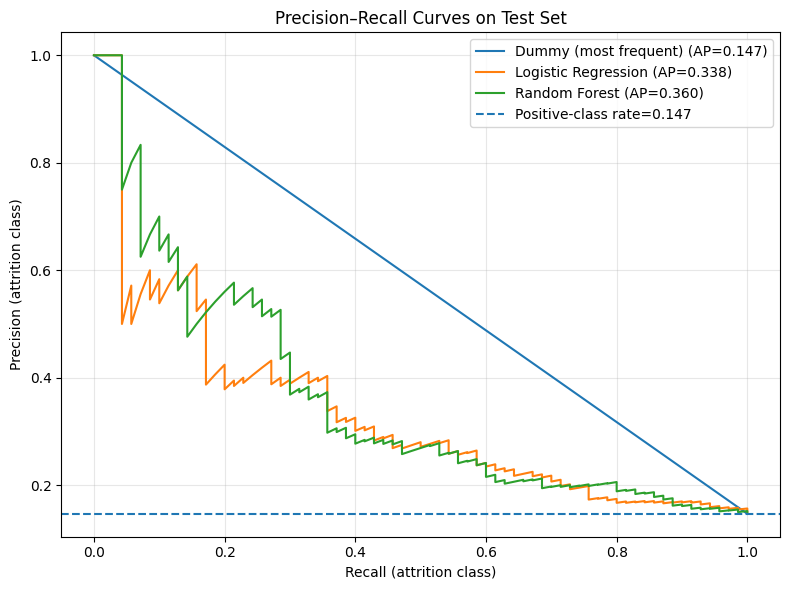

In [136]:
plt.figure(figsize=(8, 6))

for model_name, pipeline in fitted_models.items():
    if not hasattr(pipeline, "predict_proba"):
        continue
    probabilities = pipeline.predict_proba(X_test)[:, 1]
    precision, recall, _ = precision_recall_curve(y_test, probabilities)
    ap = average_precision_score(y_test, probabilities)
    plt.plot(recall, precision, label=f"{model_name} (AP={ap:.3f})")

baseline_rate = y_test.mean()
plt.axhline(baseline_rate, linestyle="--", label=f"Positive-class rate={baseline_rate:.3f}")
plt.xlabel("Recall (attrition class)")
plt.ylabel("Precision (attrition class)")
plt.title("Precision–Recall Curves on Test Set")
plt.legend()
plt.grid(True, alpha=0.3)
plt.tight_layout()
plt.show()

## 13 — Inspect confusion matrix and classification report

Use the default 0.5 probability threshold here for a consistent first comparison. Do not assume 0.5 is the final business threshold; threshold selection belongs on validation data and should reflect the cost of missed leavers versus unnecessary follow-up.

In [137]:
# Pick the leading candidate by average precision, with recall as a tie-breaker.
# This is a provisional selection rule, not a deployment decision.
candidate_name = results_df.iloc[0]["model"]
candidate_model = fitted_models[candidate_name]

print("Provisional candidate:", candidate_name)
test_predictions = candidate_model.predict(X_test)
test_probabilities = candidate_model.predict_proba(X_test)[:, 1]

print("\nConfusion matrix (rows=true, columns=predicted; order [0, 1]):")
display(pd.DataFrame(
    confusion_matrix(y_test, test_predictions, labels=[0, 1]),
    index=["Actual stayed (0)", "Actual left (1)"],
    columns=["Predicted stayed (0)", "Predicted left (1)"]
))

print("\nClassification report:")
print(classification_report(
    y_test, test_predictions,
    labels=[0, 1],
    target_names=["Stayed (0)", "Left (1)"],
    zero_division=0
))

Provisional candidate: Random Forest

Confusion matrix (rows=true, columns=predicted; order [0, 1]):


,Predicted stayed (0),Predicted left (1)
Actual stayed (0),405,2
Actual left (1),65,5



Classification report:
              precision    recall  f1-score   support

  Stayed (0)       0.86      1.00      0.92       407
    Left (1)       0.71      0.07      0.13        70

    accuracy                           0.86       477
   macro avg       0.79      0.53      0.53       477
weighted avg       0.84      0.86      0.81       477



## 14 — Review false negatives and false positives

A false negative is an employee who left but the model did not flag. A false positive is an employee flagged by the model who stayed. Review these patterns to understand trade-offs; avoid treating predictions as certainty about an individual.

In [138]:
error_review = X_test.copy()
error_review["actual_left_within_12m"] = y_test
error_review["predicted_left_within_12m"] = test_predictions
error_review["predicted_probability"] = test_probabilities

error_review["error_type"] = np.select(
    [
        (error_review["actual_left_within_12m"] == 1) & (error_review["predicted_left_within_12m"] == 0),
        (error_review["actual_left_within_12m"] == 0) & (error_review["predicted_left_within_12m"] == 1),
    ],
    ["False negative", "False positive"],
    default="Correct"
)

display(error_review[error_review["error_type"] != "Correct"].head(20))
error_path = REPORT_DIR / "test_error_review.csv"
error_review.to_csv(error_path, index=False)
print("Saved error review:", error_path)

,department_id,role_id,job_level,work_location,work_mode,employment_type,highest_education,tenure_months,total_experience_years,previous_employers_count,commute_distance_km,annual_fixed_pay,comp_ratio,raises_received,last_raise_pct,months_since_last_raise,promotions_received,months_since_last_promotion,internal_transfers,last_performance_rating,last_engagement_score,manager_changes_12m,training_hours_12m,attendance_rate_3m,late_arrivals_3m,avg_overtime_hours_per_month_3m,avg_hours_worked_3m,wfh_share_3m,unpaid_leave_days_6m,paid_leave_days_6m,never_promoted,actual_left_within_12m,predicted_left_within_12m,predicted_probability,error_type
1815,D04,R023,2,Hyderabad,Hybrid,Permanent,BBA,34.0,3.2,3,9.1,563160,0.805,3,16.8,20,1,19.0,1,2.0,NaN,0,11.5,0.9127,0,0.00,8.55,0.373,1.0,4,0,1,0,0.295032,False negative
532,D09,R051,2,Bengaluru,Hybrid,Fixed-Term Contract,Diploma Engineering,135.0,13.6,1,6.0,462828,1.089,6,7.2,25,3,132.0,0,4.0,3.0,0,7.6,0.8973,1,11.17,8.84,0.418,4.0,3,0,1,0,0.239815,False negative
1821,D06,R036,4,Hyderabad,Hybrid,Permanent,B.E. Electronics,3.0,11.9,3,7.0,604128,0.752,0,NaN,3,0,NaN,0,NaN,NaN,0,11.0,0.8857,3,0.00,8.56,0.432,0.0,8,1,1,0,0.254445,False negative
783,D09,R051,2,Delhi NCR,Onsite,Permanent,Diploma Engineering,45.0,6.0,2,24.5,409176,1.091,3,13.3,18,1,25.0,0,3.0,3.3,0,17.1,0.9368,6,11.79,8.80,-0.021,1.0,4,0,1,0,0.317311,False negative
307,D01,R004,2,Bengaluru,Remote,Permanent,M.Tech,12.0,3.2,2,13.4,621372,0.851,1,5.8,5,0,NaN,0,3.0,4.4,0,8.7,0.9844,1,0.00,8.51,0.922,1.0,5,1,1,0,0.113649,False negative
1729,D04,R024,3,Bengaluru,Onsite,Permanent,BBA,91.0,14.7,4,10.4,1380924,1.141,6,13.6,16,2,16.0,0,4.0,NaN,1,10.9,0.9434,3,0.00,8.87,0.018,1.0,8,0,1,0,0.282868,False negative
871,D07,R039,1,Bengaluru,Onsite,Permanent,MBA HR,21.0,-0.2,0,7.9,236412,0.877,1,5.0,20,0,NaN,0,2.0,3.9,0,7.7,0.9244,1,10.15,8.70,0.011,3.0,4,1,1,0,0.441897,False negative
107,D03,R016,2,Hyderabad,Hybrid,Permanent,MCA,49.0,7.9,1,17.1,713208,0.862,2,2.9,17,0,NaN,0,1.0,3.2,0,29.6,0.9844,4,0.00,8.64,0.281,0.0,3,1,1,0,0.274766,False negative
571,D04,R022,1,Pune,Onsite,Permanent,B.Com,44.0,5.1,0,10.6,336984,1.038,2,14.2,1,1,12.0,0,2.0,2.0,2,41.1,0.9335,5,0.00,9.23,0.059,3.0,6,0,1,0,0.418947,False negative
1900,D01,R003,2,Pune,Onsite,Permanent,MCA,21.0,5.8,2,24.6,976176,1.311,2,17.5,8,1,15.0,0,3.0,2.5,2,16.0,0.8377,5,0.00,9.05,-0.024,3.0,7,0,1,0,0.362029,False negative


Saved error review: d:\employee-attrition-ml\reports\task2\test_error_review.csv


## 15 — Select and save the provisional baseline pipeline

We save the **entire fitted pipeline** (preprocessing + model), not only the estimator. The saved artifact can accept raw feature columns with the same names and apply the same imputation/encoding/scaling.

Before production use, add proper temporal validation if data spans multiple observation dates, assess calibration and fairness, and set an operational threshold with stakeholders.

In [139]:
best_model_name = candidate_name
best_pipeline = fitted_models[best_model_name]

model_path = MODEL_DIR / "attrition_baseline_pipeline.joblib"
metadata_path = MODEL_DIR / "attrition_baseline_metadata.json"
feature_list_path = REPORT_DIR / "task2_feature_list.json"

joblib.dump(best_pipeline, model_path)

metadata = {
    "task": "Task 2 baseline model",
    "target": TARGET,
    "selected_model": best_model_name,
    "selection_rule": "Highest average precision on the initial held-out test set; recall used as tie-breaker",
    "random_state": RANDOM_STATE,
    "test_size": 0.20,
    "training_rows": int(len(X_train)),
    "test_rows": int(len(X_test)),
    "candidate_features": X.columns.tolist(),
    "excluded_columns": excluded_columns,
    "warning": "Provisional baseline only; validate temporal split, leakage safety, calibration, fairness, and threshold before operational use."
}
metadata_path.write_text(json.dumps(metadata, indent=2), encoding="utf-8")
feature_list_path.write_text(json.dumps(X.columns.tolist(), indent=2), encoding="utf-8")

print("Saved model:", model_path.resolve())
print("Saved metadata:", metadata_path.resolve())
print("Saved feature list:", feature_list_path.resolve())

Saved model: D:\employee-attrition-ml\artifacts\models\attrition_baseline_pipeline.joblib
Saved metadata: D:\employee-attrition-ml\artifacts\models\attrition_baseline_metadata.json
Saved feature list: D:\employee-attrition-ml\reports\task2\task2_feature_list.json


## 16 — Save a compact final metrics report

In [140]:
selected_metrics = results_df.loc[results_df["model"] == best_model_name].iloc[0].to_dict()
summary = {
    "selected_model": best_model_name,
    "test_metrics": {k: (float(v) if pd.notna(v) and isinstance(v, (int, float, np.number)) else None)
                     for k, v in selected_metrics.items() if k != "model"},
    "model_path": str(model_path),
    "metadata_path": str(metadata_path),
    "feature_count": int(X.shape[1]),
    "training_rows": int(len(X_train)),
    "test_rows": int(len(X_test)),
}
summary_path = REPORT_DIR / "task2_baseline_summary.json"
summary_path.write_text(json.dumps(summary, indent=2), encoding="utf-8")
print(json.dumps(summary, indent=2))

{
  "selected_model": "Random Forest",
  "test_metrics": {
    "accuracy": 0.859538784067086,
    "precision_attrition": 0.7142857142857143,
    "recall_attrition": 0.07142857142857142,
    "f1_attrition": 0.12987012987012986,
    "roc_auc": 0.684134784134784,
    "average_precision": 0.3599044959707579
  },
  "model_path": "d:\\employee-attrition-ml\\artifacts\\models\\attrition_baseline_pipeline.joblib",
  "metadata_path": "d:\\employee-attrition-ml\\artifacts\\models\\attrition_baseline_metadata.json",
  "feature_count": 31,
  "training_rows": 1906,
  "test_rows": 477
}


## 17 — Reload the saved artifact and verify it works

This is a small smoke test to catch a broken or incomplete save. It is not a substitute for automated tests.

In [141]:
reloaded_pipeline = joblib.load(model_path)

sample = X_test.iloc[[0]].copy()
sample_prediction = int(reloaded_pipeline.predict(sample)[0])
sample_probability = float(reloaded_pipeline.predict_proba(sample)[0, 1])

print("Reloaded artifact:", model_path.name)
print("Sample prediction (1 = left within 12 months):", sample_prediction)
print("Sample predicted probability:", round(sample_probability, 4))

assert sample_prediction in (0, 1)
assert 0.0 <= sample_probability <= 1.0
print("Smoke test passed.")

Reloaded artifact: attrition_baseline_pipeline.joblib
Sample prediction (1 = left within 12 months): 0
Sample predicted probability: 0.1829
Smoke test passed.


---

# Task 3 — Attrition Baseline Models & Evaluation

**Objective:** establish reliable baseline results for the employee attrition prediction problem. Compare a simple “everyone stays” reference model with Logistic Regression and a shallow Decision Tree, use 5-fold stratified cross-validation on the training split, compare class-weight strategies, and document the final metrics in plain language.

## Task 3 flow

1. Confirm the Task 2 training/test objects and target definition
2. Define evaluation metrics that focus on the attrition class
3. Create a 5-fold stratified cross-validation strategy
4. Compare Dummy, Logistic Regression, and shallow Decision Tree baselines
5. Compare unweighted and class-weighted versions of the real models
6. Select a provisional candidate using training cross-validation only
7. Evaluate the selected candidate on the held-out test split
8. Review confusion matrix, ROC curve, and classification report
9. Save CV results, final test metrics, and a plain-language baseline report

**Evaluation note:** Task 2 already displayed test-set results in this combined notebook. Therefore, the test set is not a completely untouched holdout anymore. Task 3 will use cross-validation on `X_train` for model comparison and use `X_test` only for its final check, but for a strict future benchmark, refactor the workflow so the test set is not inspected until the final evaluation.

## 1 — Verify the expected Task 2 objects

In [142]:
required_objects = [
    "X_train", "X_test", "y_train", "y_test",
    "preprocessor", "TARGET", "PROJECT_ROOT"
]
missing_objects = [name for name in required_objects if name not in globals()]
if missing_objects:
    raise RuntimeError(
        f"Missing Task 2 objects: {missing_objects}. Run Task 1 and Task 2 cells from the top first."
    )

print("Training rows:", len(X_train))
print("Test rows:", len(X_test))
print("Target:", TARGET)
print("Training predictors:", X_train.shape[1])
print("Target classes:", sorted(pd.Series(y_train).unique().tolist()))

assert TARGET == "left_within_12m"
assert set(pd.Series(y_train).dropna().unique()).issubset({0, 1})
assert set(pd.Series(y_test).dropna().unique()).issubset({0, 1})

Training rows: 1906
Test rows: 477
Target: left_within_12m
Training predictors: 31
Target classes: [0, 1]


## 2 — Define metrics for attrition prediction

In [143]:
from sklearn.model_selection import StratifiedKFold, cross_validate
from sklearn.tree import DecisionTreeClassifier
from sklearn.metrics import (
    ConfusionMatrixDisplay, RocCurveDisplay,
    balanced_accuracy_score
)
from sklearn.base import clone
from sklearn.dummy import DummyClassifier
from sklearn.linear_model import LogisticRegression
from sklearn.pipeline import Pipeline
from sklearn.metrics import (
    accuracy_score, precision_score, recall_score, f1_score,
    roc_auc_score, average_precision_score, confusion_matrix,
    classification_report
)
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import json

SCORING = {
    "precision": "precision",
    "recall": "recall",
    "f1": "f1",
    "roc_auc": "roc_auc",
    "average_precision": "average_precision",
    "balanced_accuracy": "balanced_accuracy",
}

print("Positive class = 1 (employee left within 12 months)")
print("Primary metrics: recall, precision, F1, ROC-AUC, average precision")

Positive class = 1 (employee left within 12 months)
Primary metrics: recall, precision, F1, ROC-AUC, average precision


## 3 — Configure 5-fold stratified cross-validation

In [144]:
cv = StratifiedKFold(
    n_splits=5,
    shuffle=True,
    random_state=RANDOM_STATE
)

fold_counts = pd.Series(y_train).value_counts().sort_index()
display(fold_counts.rename(index={0: "Stayed (0)", 1: "Left (1)"}).to_frame("training_count"))

if fold_counts.min() < cv.get_n_splits():
    raise ValueError(
        "The minority class has fewer rows than CV folds. Reduce n_splits or investigate the labels."
    )

print("CV folds:", cv.get_n_splits())

,training_count
left_within_12m,
Stayed (0),1627
Left (1),279


CV folds: 5


## 4 — Define the baseline candidates

In [145]:
# Dummy prior model predicts the majority class (normally 'stayed') for every employee.
# Real models compare class_weight=None against class_weight='balanced'.
candidate_specs = {
    "Dummy — majority class": DummyClassifier(strategy="prior"),
    "Logistic Regression — unweighted": LogisticRegression(
        max_iter=2000, class_weight=None, random_state=RANDOM_STATE
    ),
    "Logistic Regression — balanced": LogisticRegression(
        max_iter=2000, class_weight="balanced", random_state=RANDOM_STATE
    ),
    "Shallow Decision Tree — unweighted": DecisionTreeClassifier(
        max_depth=3, min_samples_leaf=20, class_weight=None,
        random_state=RANDOM_STATE
    ),
    "Shallow Decision Tree — balanced": DecisionTreeClassifier(
        max_depth=3, min_samples_leaf=20, class_weight="balanced",
        random_state=RANDOM_STATE
    ),
}

print("Candidates:")
for name in candidate_specs:
    print("-", name)

Candidates:
- Dummy — majority class
- Logistic Regression — unweighted
- Logistic Regression — balanced
- Shallow Decision Tree — unweighted
- Shallow Decision Tree — balanced


## 5 — Run cross-validation on training data only

In [146]:
cv_rows = []
cv_fitted_pipelines = {}

for name, estimator in candidate_specs.items():
    pipeline = Pipeline(steps=[
        ("preprocessor", clone(preprocessor)),
        ("model", estimator)
    ])

    scores = cross_validate(
        pipeline,
        X_train,
        y_train,
        cv=cv,
        scoring=SCORING,
        return_train_score=False,
        n_jobs=-1,
        error_score="raise"
    )

    row = {"model": name}
    for metric in SCORING:
        values = scores[f"test_{metric}"]
        row[f"{metric}_mean"] = float(np.mean(values))
        row[f"{metric}_std"] = float(np.std(values, ddof=1))
    cv_rows.append(row)

    # Fit a pipeline on all training data for the final held-out test check.
    pipeline.fit(X_train, y_train)
    cv_fitted_pipelines[name] = pipeline

cv_results = pd.DataFrame(cv_rows).sort_values(
    by=["average_precision_mean", "recall_mean", "f1_mean"],
    ascending=False
).reset_index(drop=True)

display(cv_results.round(4))

,model,precision_mean,precision_std,recall_mean,recall_std,f1_mean,f1_std,roc_auc_mean,roc_auc_std,average_precision_mean,average_precision_std,balanced_accuracy_mean,balanced_accuracy_std
0,Logistic Regression — unweighted,0.4028,0.1414,0.0860,0.0263,0.1402,0.0398,0.7048,0.0298,0.3123,0.0421,0.5313,0.0137
1,Logistic Regression — balanced,0.2589,0.0245,0.5844,0.0466,0.3582,0.0278,0.7014,0.0218,0.3083,0.0450,0.6477,0.0250
2,Shallow Decision Tree — unweighted,0.2624,0.1605,0.0863,0.0669,0.1252,0.0930,0.6421,0.0252,0.2411,0.0454,0.5275,0.0241
3,Shallow Decision Tree — balanced,0.2369,0.0347,0.5306,0.1791,0.3196,0.0436,0.6230,0.0614,0.2254,0.0452,0.6132,0.0400
4,Dummy — majority class,0.0000,0.0000,0.0000,0.0000,0.0000,0.0000,0.5000,0.0000,0.1464,0.0011,0.5000,0.0000


## 6 — Saving cross-validation comparison

In [147]:
task3_report_dir = PROJECT_ROOT / "reports" / "task3"
task3_model_dir = PROJECT_ROOT / "artifacts" / "models"
task3_report_dir.mkdir(parents=True, exist_ok=True)
task3_model_dir.mkdir(parents=True, exist_ok=True)

cv_results_path = task3_report_dir / "task3_cross_validation_results.csv"
cv_results.to_csv(cv_results_path, index=False)

print("Saved:", cv_results_path.resolve())

Saved: D:\employee-attrition-ml\reports\task3\task3_cross_validation_results.csv


## 7 — Select a provisional candidate from cross-validation

This selection uses **training cross-validation metrics only**, not test-set scores. Average precision is the primary ranking metric because attrition is the minority class; recall and F1 are tie-breakers. Business stakeholders may prefer a different trade-off depending on the cost of missed attrition versus unnecessary follow-up.

In [148]:
selected_name = cv_results.iloc[0]["model"]
selected_pipeline = cv_fitted_pipelines[selected_name]

print("Provisional model selected from CV:", selected_name)
display(cv_results.loc[cv_results["model"] == selected_name].round(4))

Provisional model selected from CV: Logistic Regression — unweighted


,model,precision_mean,precision_std,recall_mean,recall_std,f1_mean,f1_std,roc_auc_mean,roc_auc_std,average_precision_mean,average_precision_std,balanced_accuracy_mean,balanced_accuracy_std
0,Logistic Regression — unweighted,0.4028,0.1414,0.086,0.0263,0.1402,0.0398,0.7048,0.0298,0.3123,0.0421,0.5313,0.0137


## 8 — Final held-out test evaluation

In [149]:
# This is the final check for Task 3. Reminder: Task 2 had already inspected this test split.
test_pred = selected_pipeline.predict(X_test)
test_prob = selected_pipeline.predict_proba(X_test)[:, 1]

test_metrics = {
    "selected_model": selected_name,
    "accuracy": float(accuracy_score(y_test, test_pred)),
    "balanced_accuracy": float(balanced_accuracy_score(y_test, test_pred)),
    "precision_attrition": float(precision_score(y_test, test_pred, zero_division=0)),
    "recall_attrition": float(recall_score(y_test, test_pred, zero_division=0)),
    "f1_attrition": float(f1_score(y_test, test_pred, zero_division=0)),
    "roc_auc": float(roc_auc_score(y_test, test_prob)),
    "average_precision": float(average_precision_score(y_test, test_prob)),
}

display(pd.DataFrame([test_metrics]).set_index("selected_model").T.rename(columns={selected_name: "test_value"}).round(4))

selected_model,test_value
accuracy,0.8532
balanced_accuracy,0.5532
precision_attrition,0.5000
recall_attrition,0.1286
f1_attrition,0.2045
roc_auc,0.6834
average_precision,0.3268


## 9 — Confusion matrix and classification report

In [150]:
cm = confusion_matrix(y_test, test_pred, labels=[0, 1])
cm_df = pd.DataFrame(
    cm,
    index=["Actual stayed (0)", "Actual left (1)"],
    columns=["Predicted stayed (0)", "Predicted left (1)"]
)
display(cm_df)

print(classification_report(
    y_test,
    test_pred,
    labels=[0, 1],
    target_names=["Stayed (0)", "Left (1)"],
    zero_division=0
))

,Predicted stayed (0),Predicted left (1)
Actual stayed (0),398,9
Actual left (1),61,9


              precision    recall  f1-score   support

  Stayed (0)       0.87      0.98      0.92       407
    Left (1)       0.50      0.13      0.20        70

    accuracy                           0.85       477
   macro avg       0.68      0.55      0.56       477
weighted avg       0.81      0.85      0.81       477



## 10 — Plot ROC curve

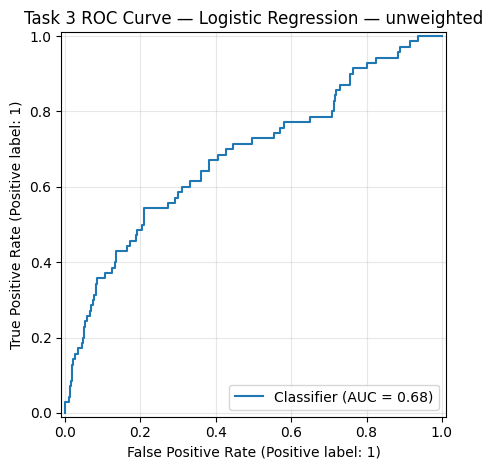

In [151]:
RocCurveDisplay.from_predictions(y_test, test_prob)
plt.title(f"Task 3 ROC Curve — {selected_name}")
plt.grid(True, alpha=0.3)
plt.tight_layout()
plt.show()

## 11 — Inspect test errors

In [152]:
task3_errors = X_test.copy()
task3_errors["actual_left_within_12m"] = np.asarray(y_test)
task3_errors["predicted_left_within_12m"] = test_pred
task3_errors["predicted_probability"] = test_prob
task3_errors["error_type"] = np.select(
    [
        (task3_errors["actual_left_within_12m"] == 1) & (task3_errors["predicted_left_within_12m"] == 0),
        (task3_errors["actual_left_within_12m"] == 0) & (task3_errors["predicted_left_within_12m"] == 1),
    ],
    ["False negative", "False positive"],
    default="Correct"
)

display(task3_errors[task3_errors["error_type"] != "Correct"].head(25))
errors_path = task3_report_dir / "task3_test_error_review.csv"
task3_errors.to_csv(errors_path, index=False)
print("Saved:", errors_path.resolve())

,department_id,role_id,job_level,work_location,work_mode,employment_type,highest_education,tenure_months,total_experience_years,previous_employers_count,commute_distance_km,annual_fixed_pay,comp_ratio,raises_received,last_raise_pct,months_since_last_raise,promotions_received,months_since_last_promotion,internal_transfers,last_performance_rating,last_engagement_score,manager_changes_12m,training_hours_12m,attendance_rate_3m,late_arrivals_3m,avg_overtime_hours_per_month_3m,avg_hours_worked_3m,wfh_share_3m,unpaid_leave_days_6m,paid_leave_days_6m,never_promoted,actual_left_within_12m,predicted_left_within_12m,predicted_probability,error_type
1815,D04,R023,2,Hyderabad,Hybrid,Permanent,BBA,34.0,3.2,3,9.1,563160,0.805,3,16.8,20,1,19.0,1,2.0,NaN,0,11.5,0.9127,0,0.00,8.55,0.373,1.0,4,0,1,0,0.113827,False negative
532,D09,R051,2,Bengaluru,Hybrid,Fixed-Term Contract,Diploma Engineering,135.0,13.6,1,6.0,462828,1.089,6,7.2,25,3,132.0,0,4.0,3.0,0,7.6,0.8973,1,11.17,8.84,0.418,4.0,3,0,1,0,0.049904,False negative
2009,D02,R013,4,Bengaluru,Onsite,Permanent,B.Des,31.0,14.1,2,20.0,2535948,0.938,3,7.0,24,0,NaN,0,4.0,4.5,1,16.6,0.9162,5,0.00,8.57,0.139,0.0,4,1,0,1,0.500436,False positive
1821,D06,R036,4,Hyderabad,Hybrid,Permanent,B.E. Electronics,3.0,11.9,3,7.0,604128,0.752,0,NaN,3,0,NaN,0,NaN,NaN,0,11.0,0.8857,3,0.00,8.56,0.432,0.0,8,1,1,0,0.263319,False negative
783,D09,R051,2,Delhi NCR,Onsite,Permanent,Diploma Engineering,45.0,6.0,2,24.5,409176,1.091,3,13.3,18,1,25.0,0,3.0,3.3,0,17.1,0.9368,6,11.79,8.80,-0.021,1.0,4,0,1,0,0.136716,False negative
307,D01,R004,2,Bengaluru,Remote,Permanent,M.Tech,12.0,3.2,2,13.4,621372,0.851,1,5.8,5,0,NaN,0,3.0,4.4,0,8.7,0.9844,1,0.00,8.51,0.922,1.0,5,1,1,0,0.038381,False negative
1729,D04,R024,3,Bengaluru,Onsite,Permanent,BBA,91.0,14.7,4,10.4,1380924,1.141,6,13.6,16,2,16.0,0,4.0,NaN,1,10.9,0.9434,3,0.00,8.87,0.018,1.0,8,0,1,0,0.129389,False negative
1781,D06,R033,1,Pune,Onsite,Permanent,B.Com,89.0,8.6,0,10.1,225204,1.018,6,14.6,39,5,22.0,0,3.0,3.7,1,13.7,0.9176,8,11.70,9.04,0.039,3.0,4,0,0,1,0.680873,False positive
871,D07,R039,1,Bengaluru,Onsite,Permanent,MBA HR,21.0,-0.2,0,7.9,236412,0.877,1,5.0,20,0,NaN,0,2.0,3.9,0,7.7,0.9244,1,10.15,8.70,0.011,3.0,4,1,1,0,0.392631,False negative
107,D03,R016,2,Hyderabad,Hybrid,Permanent,MCA,49.0,7.9,1,17.1,713208,0.862,2,2.9,17,0,NaN,0,1.0,3.2,0,29.6,0.9844,4,0.00,8.64,0.281,0.0,3,1,1,0,0.199973,False negative


Saved: D:\employee-attrition-ml\reports\task3\task3_test_error_review.csv


## 12 — Save final metrics, selected pipeline, and metadata

In [153]:
import joblib

task3_model_path = task3_model_dir / "attrition_task3_selected_baseline.joblib"
task3_metrics_path = task3_report_dir / "task3_final_test_metrics.json"
task3_metadata_path = task3_model_dir / "attrition_task3_metadata.json"

joblib.dump(selected_pipeline, task3_model_path)

task3_metadata = {
    "task": "Task 3 — Attrition Baseline Models & Evaluation",
    "target": TARGET,
    "selected_model": selected_name,
    "selection_basis": "5-fold stratified CV on training split; ranked by average precision, then recall and F1",
    "cv_folds": 5,
    "random_state": RANDOM_STATE,
    "feature_columns": X_train.columns.tolist(),
    "warning": (
        "The test split was already inspected during Task 2 in this combined notebook. "
        "Use a fresh locked test set in a future strict evaluation workflow."
    )
}

task3_metrics_path.write_text(json.dumps(test_metrics, indent=2), encoding="utf-8")
task3_metadata_path.write_text(json.dumps(task3_metadata, indent=2), encoding="utf-8")

print("Saved model:", task3_model_path.resolve())
print("Saved test metrics:", task3_metrics_path.resolve())
print("Saved metadata:", task3_metadata_path.resolve())

Saved model: D:\employee-attrition-ml\artifacts\models\attrition_task3_selected_baseline.joblib
Saved test metrics: D:\employee-attrition-ml\reports\task3\task3_final_test_metrics.json
Saved metadata: D:\employee-attrition-ml\artifacts\models\attrition_task3_metadata.json


## 13 — Generate a plain-language baseline report

In [154]:
best_cv_row = cv_results.loc[cv_results["model"] == selected_name].iloc[0]

report_text = f"""# Task 3 — Attrition Baseline Report

## Objective
Compare a majority-class reference model with Logistic Regression and a shallow Decision Tree for predicting whether an employee leaves within 12 months.

## Data and validation
- Training rows: {len(X_train)}
- Held-out test rows: {len(X_test)}
- Predictor count: {X_train.shape[1]}
- Validation: 5-fold stratified cross-validation on the training split.
- Target: `{TARGET}` (1 = left within 12 months).

## Provisional model
Selected from training cross-validation: **{selected_name}**.

Cross-validation mean metrics:
- Precision (attrition): {best_cv_row["precision_mean"]:.3f}
- Recall (attrition): {best_cv_row["recall_mean"]:.3f}
- F1 (attrition): {best_cv_row["f1_mean"]:.3f}
- ROC-AUC: {best_cv_row["roc_auc_mean"]:.3f}
- Average precision: {best_cv_row["average_precision_mean"]:.3f}

## Held-out test metrics
- Accuracy: {test_metrics["accuracy"]:.3f}
- Balanced accuracy: {test_metrics["balanced_accuracy"]:.3f}
- Precision (attrition): {test_metrics["precision_attrition"]:.3f}
- Recall (attrition): {test_metrics["recall_attrition"]:.3f}
- F1 (attrition): {test_metrics["f1_attrition"]:.3f}
- ROC-AUC: {test_metrics["roc_auc"]:.3f}
- Average precision: {test_metrics["average_precision"]:.3f}

## Interpretation
Read precision and recall together. Higher recall means more actual leavers are identified, while higher precision means fewer flagged employees are false alarms. The appropriate balance depends on the cost and capacity of follow-up interventions. The model must not be used to make automatic employment decisions.

## Limitations and next steps
- The test split was already inspected during Task 2 in this combined notebook, so these results are not a pristine final benchmark.
- Confirm predictors are available at the intended prediction date and that no post-outcome information is present.
- Use temporal validation if the production use case predicts future periods.
- Review fairness, probability calibration, threshold selection, and performance drift before any operational use.
"""

report_path = task3_report_dir / "task3_baseline_report.md"
report_path.write_text(report_text, encoding="utf-8")
print(report_text)
print("\nSaved:", report_path.resolve())

# Task 3 — Attrition Baseline Report

## Objective
Compare a majority-class reference model with Logistic Regression and a shallow Decision Tree for predicting whether an employee leaves within 12 months.

## Data and validation
- Training rows: 1906
- Held-out test rows: 477
- Predictor count: 31
- Validation: 5-fold stratified cross-validation on the training split.
- Target: `left_within_12m` (1 = left within 12 months).

## Provisional model
Selected from training cross-validation: **Logistic Regression — unweighted**.

Cross-validation mean metrics:
- Precision (attrition): 0.403
- Recall (attrition): 0.086
- F1 (attrition): 0.140
- ROC-AUC: 0.705
- Average precision: 0.312

## Held-out test metrics
- Accuracy: 0.853
- Balanced accuracy: 0.553
- Precision (attrition): 0.500
- Recall (attrition): 0.129
- F1 (attrition): 0.205
- ROC-AUC: 0.683
- Average precision: 0.327

## Interpretation
Read precision and recall together. Higher recall means more actual leavers are identified, whi

---

# Task 4 — Attendance Anomaly Detection

**Objective:** identify unusual attendance patterns for review using attendance-related fields available in the dataset. An anomaly is a review signal, not proof of misconduct or a reason to make an employment decision automatically.

## Task 4 flow
1. Confirm Tasks 1–3 have run and inspect attendance-related fields.
2. Select attendance features based on the actual dataset schema.
3. Validate types, missingness, ranges, and duplicates.
4. Create an attendance-only analysis table without changing the source dataset.
5. Establish transparent rule-based flags.
6. Fit an Isolation Forest detector on numeric attendance features.
7. Compare anomaly scores and flags.
8. Inspect high-scoring records and feature distributions.
9. Save scores, flagged records, configuration, and a plain-language report.

**Scope note:** attendance-specific fields are not confirmed in the currently described dataset. This task detects actual available fields and stops if none exist. It will not substitute unrelated fields such as salary or performance.

## 1 — Verify prior tasks and imports

In [155]:
from pathlib import Path
import json
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from sklearn.impute import SimpleImputer
from sklearn.pipeline import Pipeline
from sklearn.preprocessing import StandardScaler
from sklearn.ensemble import IsolationForest

required_previous = ["PROJECT_ROOT", "df"]
missing_previous = [name for name in required_previous if name not in globals()]
if missing_previous:
    raise RuntimeError(f"Missing objects: {missing_previous}. Run Tasks 1–3 from the top first.")

print("Project root:", PROJECT_ROOT.resolve())
print("Dataset shape:", df.shape)
print("Anomaly detection will not use the attrition target as a training feature.")

Project root: D:\employee-attrition-ml
Dataset shape: (2383, 43)
Anomaly detection will not use the attrition target as a training feature.


## 2 — Discover attendance-related columns

In [156]:
attendance_keywords = (
    "attendance", "absen", "absence", "absent", "present",
    "late", "lateness", "tardy", "punctual", "overtime",
    "leave_days", "sick_days", "unplanned", "no_show",
    "missed_days", "days_off", "shift_adherence"
)
attendance_columns = [
    col for col in df.columns
    if any(keyword in col.lower() for keyword in attendance_keywords)
]

print("Detected attendance-related columns:", attendance_columns)
if not attendance_columns:
    raise ValueError(
        "No attendance-related columns were found. Stop here and confirm the separate attendance "
        "dataset or correct schema. Do not use unrelated HR fields for this task."
    )
display(df[attendance_columns].head())

Detected attendance-related columns: ['attendance_rate_3m', 'late_arrivals_3m', 'avg_overtime_hours_per_month_3m', 'unpaid_leave_days_6m', 'paid_leave_days_6m']


,attendance_rate_3m,late_arrivals_3m,avg_overtime_hours_per_month_3m,unpaid_leave_days_6m,paid_leave_days_6m
0,0.9219,3,0.00,2.0,5
1,0.9688,1,0.00,1.0,4
2,0.9453,0,4.33,1.0,7
3,0.9375,4,0.00,0.0,8
4,0.8906,10,0.00,0.0,7


## 3 — Profile candidate fields

In [157]:
attendance_profile = pd.DataFrame({
    "dtype": df[attendance_columns].dtypes.astype(str),
    "missing_count": df[attendance_columns].isna().sum(),
    "missing_pct": (df[attendance_columns].isna().mean() * 100).round(2),
    "unique_values": df[attendance_columns].nunique(dropna=True),
}).sort_values("missing_pct", ascending=False)
display(attendance_profile)

attendance_numeric = df[attendance_columns].select_dtypes(include=np.number).columns.tolist()
if attendance_numeric:
    display(df[attendance_numeric].describe().T)
else:
    print("No numeric attendance fields detected; review schema and define justified encoding.")

,dtype,missing_count,missing_pct,unique_values
attendance_rate_3m,float64,0,0.0,1051
late_arrivals_3m,int64,0,0.0,27
avg_overtime_hours_per_month_3m,float64,0,0.0,390
unpaid_leave_days_6m,float64,0,0.0,20
paid_leave_days_6m,int64,0,0.0,23


,count,mean,std,min,25%,50%,75%,max
attendance_rate_3m,2383.0,0.910302,0.047349,0.2031,0.8871,0.9128,0.93735,1.12
late_arrivals_3m,2383.0,4.976500,3.933467,0.0000,2.0000,4.0000,7.00000,29.00
avg_overtime_hours_per_month_3m,2383.0,2.169253,5.336391,0.0000,0.0000,0.0000,0.00000,50.00
unpaid_leave_days_6m,2383.0,1.409987,1.429485,0.0000,0.0000,1.0000,2.00000,12.00
paid_leave_days_6m,2383.0,5.420478,3.000887,0.0000,3.0000,5.0000,7.00000,51.00


## 4 — Define usable numeric features

In [158]:
attendance_features = attendance_numeric.copy()
if not attendance_features:
    raise ValueError("No numeric attendance features. Define and document a valid encoding first.")

constant_features = [c for c in attendance_features if df[c].nunique(dropna=True) <= 1]
if constant_features:
    print("Removing constant/near-empty columns:", constant_features)
    attendance_features = [c for c in attendance_features if c not in constant_features]
if not attendance_features:
    raise ValueError("No usable numeric attendance features remain.")

print("Features used:")
print(attendance_features)

Features used:
['attendance_rate_3m', 'late_arrivals_3m', 'avg_overtime_hours_per_month_3m', 'unpaid_leave_days_6m', 'paid_leave_days_6m']


## 5 — Review ranges, missingness, and negative values

In [159]:
attendance_data = df[attendance_features].copy().replace([np.inf, -np.inf], np.nan)
range_review = []
for col in attendance_features:
    s = attendance_data[col]
    range_review.append({
        "feature": col,
        "missing": int(s.isna().sum()),
        "min": s.min(),
        "median": s.median(),
        "max": s.max(),
        "negative_count": int((s < 0).sum()),
    })
range_review_df = pd.DataFrame(range_review)
display(range_review_df)
print("Confirm field definitions and units before deciding whether an extreme value is invalid.")

,feature,missing,min,median,max,negative_count
0,attendance_rate_3m,0,0.2031,0.9128,1.12,0
1,late_arrivals_3m,0,0.0000,4.0000,29.00,0
2,avg_overtime_hours_per_month_3m,0,0.0000,0.0000,50.00,0
3,unpaid_leave_days_6m,0,0.0000,1.0000,12.00,0
4,paid_leave_days_6m,0,0.0000,5.0000,51.00,0


Confirm field definitions and units before deciding whether an extreme value is invalid.


## 6 — Create a row-level review table

In [160]:
review_keys = [c for c in ["employee_id", "row_id", "observation_date"] if c in df.columns]
attendance_review = df[review_keys].copy() if review_keys else pd.DataFrame(index=df.index)
attendance_review["source_row_index"] = df.index
attendance_review = attendance_review.join(attendance_data)
display(attendance_review.head())
print("Review table shape:", attendance_review.shape)

,employee_id,row_id,observation_date,source_row_index,attendance_rate_3m,late_arrivals_3m,avg_overtime_hours_per_month_3m,unpaid_leave_days_6m,paid_leave_days_6m
0,EMP-0002,1,2025-09-30,0,0.9219,3,0.00,2.0,5
1,EMP-0004,2,2025-09-30,1,0.9688,1,0.00,1.0,4
2,EMP-0011,3,2025-09-30,2,0.9453,0,4.33,1.0,7
3,EMP-0012,4,2025-09-30,3,0.9375,4,0.00,0.0,8
4,EMP-0013,5,2025-09-30,4,0.8906,10,0.00,0.0,7


Review table shape: (2383, 9)


## 7 — Transparent rule-based flags

IQR flags identify values outside Q1 − 1.5 × IQR or Q3 + 1.5 × IQR. Negative values are separately flagged for review. These are screening rules, not proof that a value is wrong; valid operational extremes can be flagged.

In [161]:
rule_flags = pd.DataFrame(index=attendance_data.index)
rule_summary = []
for col in attendance_features:
    s = attendance_data[col]
    q1, q3 = s.quantile(0.25), s.quantile(0.75)
    iqr = q3 - q1
    lower, upper = q1 - 1.5 * iqr, q3 + 1.5 * iqr

    rule_flags[f"{col}__iqr_flag"] = ((s < lower) | (s > upper)).fillna(False)
    rule_flags[f"{col}__negative_flag"] = (s < 0).fillna(False)
    rule_summary.append({
        "feature": col,
        "lower_iqr_bound": lower,
        "upper_iqr_bound": upper,
        "iqr_flag_count": int(rule_flags[f"{col}__iqr_flag"].sum()),
        "negative_flag_count": int(rule_flags[f"{col}__negative_flag"].sum()),
    })

rule_summary_df = pd.DataFrame(rule_summary)
attendance_review = attendance_review.join(rule_flags)
attendance_review["rule_flag_count"] = rule_flags.sum(axis=1)
attendance_review["rule_anomaly_flag"] = attendance_review["rule_flag_count"] > 0
display(rule_summary_df)
print("Rows with rule-based flags:", int(attendance_review["rule_anomaly_flag"].sum()))

,feature,lower_iqr_bound,upper_iqr_bound,iqr_flag_count,negative_flag_count
0,attendance_rate_3m,0.811725,1.012725,60,0
1,late_arrivals_3m,-5.500000,14.500000,67,0
2,avg_overtime_hours_per_month_3m,0.000000,0.000000,445,0
3,unpaid_leave_days_6m,-3.000000,5.000000,38,0
4,paid_leave_days_6m,-3.000000,13.000000,23,0


Rows with rule-based flags: 585


## 8 — Fit Isolation Forest

In [162]:
# This is unsupervised: no attrition labels are passed to fit().
contamination_rate = 0.05  # Initial review-queue assumption, not a known anomaly rate.
isolation_pipeline = Pipeline(steps=[
    ("imputer", SimpleImputer(strategy="median")),
    ("scaler", StandardScaler()),
    ("isolation_forest", IsolationForest(
        n_estimators=300,
        contamination=contamination_rate,
        random_state=RANDOM_STATE if "RANDOM_STATE" in globals() else 42,
        n_jobs=-1
    ))
])
isolation_pipeline.fit(attendance_data)

decision_scores = isolation_pipeline.decision_function(attendance_data)
predicted_labels = isolation_pipeline.predict(attendance_data)
attendance_review["isolation_anomaly_score"] = -decision_scores  # higher = more anomalous
attendance_review["isolation_anomaly_flag"] = predicted_labels == -1

print("Contamination setting:", contamination_rate)
print("Isolation Forest flagged rows:", int(attendance_review["isolation_anomaly_flag"].sum()))

Contamination setting: 0.05
Isolation Forest flagged rows: 120


## 9 — Compare methods

In [163]:
comparison = pd.crosstab(
    attendance_review["rule_anomaly_flag"],
    attendance_review["isolation_anomaly_flag"],
    rownames=["Rule-based flag"],
    colnames=["Isolation Forest flag"],
    dropna=False
)
display(comparison)

attendance_review["both_methods_flag"] = (
    attendance_review["rule_anomaly_flag"] & attendance_review["isolation_anomaly_flag"]
)
attendance_review["either_method_flag"] = (
    attendance_review["rule_anomaly_flag"] | attendance_review["isolation_anomaly_flag"]
)
print("Flagged by both:", int(attendance_review["both_methods_flag"].sum()))
print("Flagged by either:", int(attendance_review["either_method_flag"].sum()))

Isolation Forest flag,False,True
Rule-based flag,,
False,1796,2
True,467,118


Flagged by both: 118
Flagged by either: 587


## 10 — Plot feature distributions

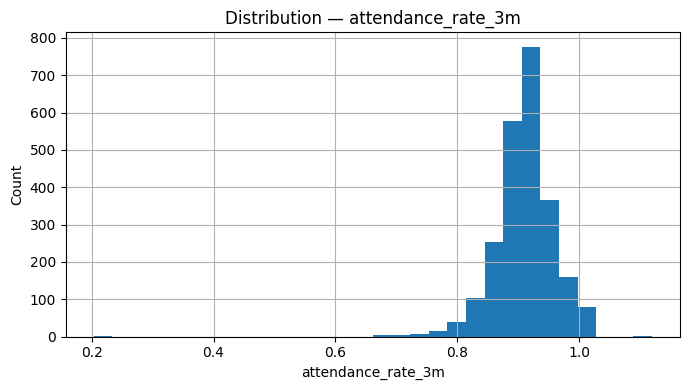

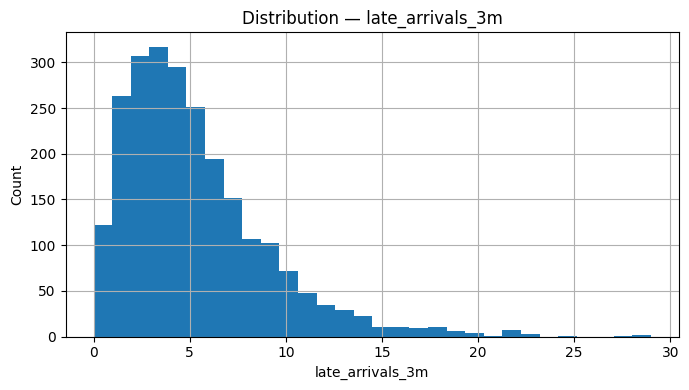

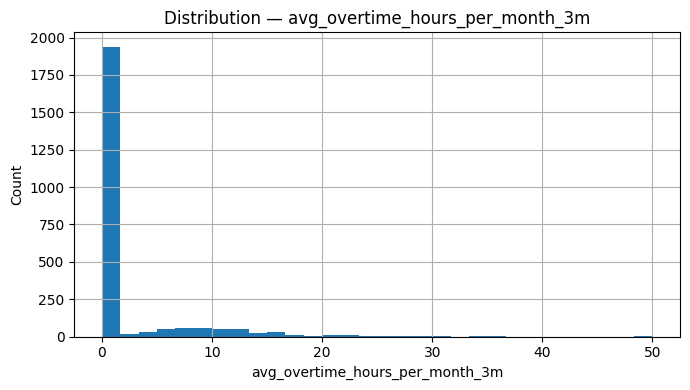

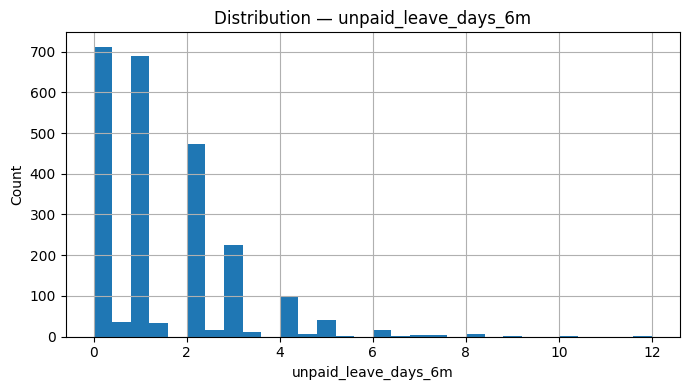

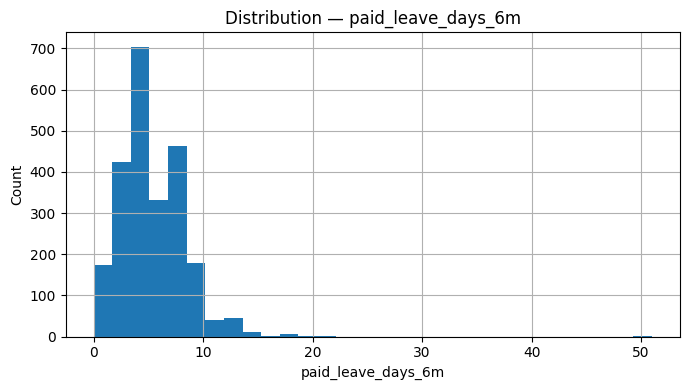

In [164]:
for col in attendance_features:
    plt.figure(figsize=(7, 4))
    attendance_data[col].dropna().hist(bins=30)
    plt.title(f"Distribution — {col}")
    plt.xlabel(col)
    plt.ylabel("Count")
    plt.tight_layout()
    plt.show()

## 11 — Inspect highest-scoring records

In [165]:
top_n = min(25, len(attendance_review))
top_anomalies = attendance_review.sort_values(
    "isolation_anomaly_score", ascending=False
).head(top_n)
display(top_anomalies)

,employee_id,row_id,observation_date,source_row_index,attendance_rate_3m,late_arrivals_3m,avg_overtime_hours_per_month_3m,unpaid_leave_days_6m,paid_leave_days_6m,attendance_rate_3m__iqr_flag,attendance_rate_3m__negative_flag,late_arrivals_3m__iqr_flag,late_arrivals_3m__negative_flag,avg_overtime_hours_per_month_3m__iqr_flag,avg_overtime_hours_per_month_3m__negative_flag,unpaid_leave_days_6m__iqr_flag,unpaid_leave_days_6m__negative_flag,paid_leave_days_6m__iqr_flag,paid_leave_days_6m__negative_flag,rule_flag_count,rule_anomaly_flag,isolation_anomaly_score,isolation_anomaly_flag,both_methods_flag,either_method_flag
411,HIST-0029,412,2022-09-26,411,0.7096,8,21.26,7.0,5,True,False,False,False,True,False,True,False,False,False,3,True,0.152956,True,True,True
2161,HIST-1779,2162,2024-08-26,2161,0.6773,2,6.76,9.0,6,True,False,False,False,True,False,True,False,False,False,3,True,0.138348,True,True,True
441,HIST-0059,442,2024-09-02,441,0.9314,22,22.14,0.0,1,False,False,True,False,True,False,False,False,False,False,2,True,0.126357,True,True,True
143,EMP-0313,144,2025-09-30,143,0.2031,1,0.00,1.0,51,True,False,False,False,False,False,False,False,True,False,2,True,0.126357,True,True,True
1893,HIST-1511,1894,2022-02-03,1893,0.6843,3,0.00,8.0,5,True,False,False,False,False,False,True,False,False,False,2,True,0.111338,True,True,True
669,HIST-0287,670,2024-03-15,669,0.9554,19,23.63,0.0,7,False,False,True,False,True,False,False,False,False,False,2,True,0.110380,True,True,True
2169,HIST-1787,2170,2024-08-08,2169,0.7111,1,0.00,8.0,3,True,False,False,False,False,False,True,False,False,False,2,True,0.109031,True,True,True
725,HIST-0343,726,2021-12-27,725,0.7154,5,0.00,10.0,6,True,False,False,False,False,False,True,False,False,False,2,True,0.108163,True,True,True
743,HIST-0361,744,2025-02-05,743,0.7393,10,0.00,5.0,12,True,False,False,False,False,False,False,False,False,False,1,True,0.089732,True,True,True
2137,HIST-1755,2138,2022-12-08,2137,0.7259,11,0.00,6.0,3,True,False,False,False,False,False,True,False,False,False,2,True,0.088456,True,True,True


## 12 — Saving review tables

In [166]:
task4_report_dir = PROJECT_ROOT / "reports" / "task4"
task4_artifact_dir = PROJECT_ROOT / "artifacts" / "models"
task4_report_dir.mkdir(parents=True, exist_ok=True)
task4_artifact_dir.mkdir(parents=True, exist_ok=True)

profile_path = task4_report_dir / "task4_attendance_profile.csv"
rules_path = task4_report_dir / "task4_rule_flag_summary.csv"
review_path = task4_report_dir / "task4_attendance_anomaly_review.csv"

attendance_profile.to_csv(profile_path)
rule_summary_df.to_csv(rules_path, index=False)
attendance_review.sort_values("isolation_anomaly_score", ascending=False).to_csv(review_path, index=False)

print("Saved:", profile_path.resolve())
print("Saved:", rules_path.resolve())
print("Saved:", review_path.resolve())

Saved: D:\employee-attrition-ml\reports\task4\task4_attendance_profile.csv
Saved: D:\employee-attrition-ml\reports\task4\task4_rule_flag_summary.csv
Saved: D:\employee-attrition-ml\reports\task4\task4_attendance_anomaly_review.csv


## Cell 13 — Save model and configuration

In [167]:
import joblib

task4_model_path = task4_artifact_dir / "attendance_isolation_forest_pipeline.joblib"
task4_config_path = task4_artifact_dir / "attendance_anomaly_config.json"
joblib.dump(isolation_pipeline, task4_model_path)

task4_config = {
    "task": "Task 4 — Attendance Anomaly Detection",
    "features": attendance_features,
    "contamination_rate": contamination_rate,
    "score_interpretation": "Higher isolation_anomaly_score means more anomalous relative to the fitted dataset.",
    "limitations": [
        "No ground-truth anomaly labels were used.",
        "Contamination rate is an initial assumption and requires domain review.",
        "Feature definitions, units, valid ranges, and reporting periods must be confirmed.",
        "Flags must not be used alone for disciplinary or employment decisions."
    ]
}
task4_config_path.write_text(json.dumps(task4_config, indent=2), encoding="utf-8")
print("Saved model:", task4_model_path.resolve())
print("Saved config:", task4_config_path.resolve())

Saved model: D:\employee-attrition-ml\artifacts\models\attendance_isolation_forest_pipeline.joblib
Saved config: D:\employee-attrition-ml\artifacts\models\attendance_anomaly_config.json


## 14 plain-language report

In [168]:
n_rows = len(attendance_review)
n_rule = int(attendance_review["rule_anomaly_flag"].sum())
n_iforest = int(attendance_review["isolation_anomaly_flag"].sum())
n_both = int(attendance_review["both_methods_flag"].sum())

report = f"""# Task 4 — Attendance Anomaly Detection Report

## Objective
Identify unusual attendance patterns for human review using IQR flags and Isolation Forest.

## Data used
- Rows analyzed: {n_rows}
- Numeric attendance features: {len(attendance_features)}
- Features: {", ".join(attendance_features)}

## Results
- Rows flagged by rule-based checks: {n_rule}
- Rows flagged by Isolation Forest: {n_iforest}
- Rows flagged by both approaches: {n_both}
- Contamination setting: {contamination_rate:.1%}

## Interpretation
These are candidate anomalies, not confirmed errors or misconduct. IQR flags are easy to explain but can flag valid extremes. Isolation Forest finds unusual combinations of numeric values but does not explain cause.

## Limitations and next steps
- Confirm each attendance field definition, unit, valid range, and reporting period.
- Review flagged records with a domain owner before taking action.
- If reviewed examples become available, measure precision and false-alarm rate on that reviewed sample.
- Consider employee-level history and seasonality if multiple time periods are available.
- Do not use anomaly flags alone for disciplinary or employment decisions.
"""

task4_report_path = task4_report_dir / "task4_attendance_anomaly_report.md"
task4_report_path.write_text(report, encoding="utf-8")
print(report)
print("Saved:", task4_report_path.resolve())

# Task 4 — Attendance Anomaly Detection Report

## Objective
Identify unusual attendance patterns for human review using IQR flags and Isolation Forest.

## Data used
- Rows analyzed: 2383
- Numeric attendance features: 5
- Features: attendance_rate_3m, late_arrivals_3m, avg_overtime_hours_per_month_3m, unpaid_leave_days_6m, paid_leave_days_6m

## Results
- Rows flagged by rule-based checks: 585
- Rows flagged by Isolation Forest: 120
- Rows flagged by both approaches: 118
- Contamination setting: 5.0%

## Interpretation
These are candidate anomalies, not confirmed errors or misconduct. IQR flags are easy to explain but can flag valid extremes. Isolation Forest finds unusual combinations of numeric values but does not explain cause.

## Limitations and next steps
- Confirm each attendance field definition, unit, valid range, and reporting period.
- Review flagged records with a domain owner before taking action.
- If reviewed examples become available, measure precision and false-alarm